In [3]:
# Day 3 - Exploratory Data Analysis (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

# Chart styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("All libraries imported successfully!")
print("Ready for Day 3 EDA 🚀")

All libraries imported successfully!
Ready for Day 3 EDA 🚀


In [2]:
from pathlib import Path

# Check current working directory
print("Current folder:", Path.cwd())

# Check project folders
print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

Current folder: c:\Users\admin\Desktop\INTERNSHIP\Mutual_Fund_Analytics\notebooks

Files and folders here:
EDA_Analysis.ipynb


In [3]:
from pathlib import Path

# Move one level up from notebooks to project root
project_root = Path.cwd().parent

print("Project Root:", project_root)
print("\nProject folders:")

for item in project_root.iterdir():
    if item.is_dir():
        print("📁", item.name)

Project Root: c:\Users\admin\Desktop\INTERNSHIP\Mutual_Fund_Analytics

Project folders:
📁 dashboard
📁 data
📁 notebooks
📁 reports
📁 sql
📁 venv


In [4]:
# Inspect the data folder
data_path = project_root / "data"

for folder in data_path.iterdir():
    print(f"\n📁 {folder.name}")
    if folder.is_dir():
        for file in folder.iterdir():
            print("   📄", file.name)


📁 processed
   📄 aum_by_fund_house_cleaned.csv
   📄 benchmark_indices_cleaned.csv
   📄 category_inflows_cleaned.csv
   📄 fund_master_cleaned.csv
   📄 industry_folio_count_cleaned.csv
   📄 investor_transactions_cleaned.csv
   📄 monthly_sip_inflows_cleaned.csv
   📄 nav_history_cleaned.csv
   📄 performance_anomalies.csv
   📄 portfolio_holdings_cleaned.csv
   📄 scheme_performance_cleaned.csv
   📄 transactions_rejected.csv

📁 raw
   📄 1788499980509-304c1255-08_investor_transactions.csv
   📄 1788499982117-e3d6ab98-09_portfolio_holdings.csv
   📄 1788499982615-f9647ab2-10_benchmark_indices.csv
   📄 1788499983024-b042c300-01_fund_master.csv
   📄 1788499983331-4389156d-02_nav_history.csv
   📄 1788499984134-b0cbf625-03_aum_by_fund_house.csv
   📄 1788499984405-d702a6c6-04_monthly_sip_inflows.csv
   📄 1788499984721-4b860901-05_category_inflows.csv
   📄 1788499985036-da4a0c4a-06_industry_folio_count.csv
   📄 1788499985420-bb134abf-07_scheme_performance.csv
   📄 live_nav_118632.csv
   📄 live_nav_119

In [5]:
# Day 3: Dataset overview

processed_path = project_root / "data" / "processed"

for file in sorted(processed_path.glob("*.csv")):
    df = pd.read_csv(file)

    print("\n" + "=" * 70)
    print("FILE:", file.name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("Total missing values:", df.isnull().sum().sum())

    # Show date range if a date/month column exists
    date_cols = [col for col in df.columns if "date" in col.lower() or "month" in col.lower()]

    for col in date_cols:
        dates = pd.to_datetime(df[col], errors="coerce").dropna()
        if not dates.empty:
            print(f"{col} range: {dates.min().date()} to {dates.max().date()}")

    print("Sample:")
    display(df.head(3))


FILE: aum_by_fund_house_cleaned.csv
Shape: (90, 5)
Columns: ['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']
Total missing values: 0
date range: 2022-03-31 to 2025-12-31
Sample:


,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195



FILE: benchmark_indices_cleaned.csv
Shape: (8050, 3)
Columns: ['date', 'index_name', 'close_value']
Total missing values: 0
date range: 2022-01-03 to 2026-05-29
Sample:


,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05



FILE: category_inflows_cleaned.csv
Shape: (144, 3)
Columns: ['month', 'category', 'net_inflow_crore']
Total missing values: 0
month range: 2024-04-01 to 2025-03-01
Sample:


,month,category,net_inflow_crore
0,2024-04-01,Large Cap,2413.0
1,2024-04-01,Mid Cap,3897.0
2,2024-04-01,Small Cap,3533.0


... (14 outputs left out)


FILE: scheme_performance_cleaned.csv
Shape: (40, 20)
Columns: ['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade', 'return_anomaly']
Total missing values: 0
Sample:


,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade,return_anomaly
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate,False
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate,False
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High,False



FILE: transactions_rejected.csv
Shape: (0, 13)
Columns: ['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']
Total missing values: 0
Sample:


,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status


In [6]:
# Check date coverage of the datasets we need for upcoming charts

files_to_check = [
    "nav_history_cleaned.csv",
    "aum_by_fund_house_cleaned.csv",
    "monthly_sip_inflows_cleaned.csv",
    "category_inflows_cleaned.csv",
    "industry_folio_count_cleaned.csv"
]

for filename in files_to_check:
    df_check = pd.read_csv(processed_path / filename)

    date_col = next(
        (col for col in df_check.columns if "date" in col.lower() or "month" in col.lower()),
        None
    )

    print(f"\n{filename}")
    print("Rows:", len(df_check))

    if date_col:
        dates = pd.to_datetime(df_check[date_col], errors="coerce").dropna()
        print("Date range:", dates.min().date(), "to", dates.max().date())

    print("Columns:", list(df_check.columns))


nav_history_cleaned.csv
Rows: 46000
Date range: 2022-01-03 to 2026-05-29
Columns: ['amfi_code', 'date', 'nav']

aum_by_fund_house_cleaned.csv
Rows: 90
Date range: 2022-03-31 to 2025-12-31
Columns: ['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']

monthly_sip_inflows_cleaned.csv
Rows: 48
Date range: 2022-01-01 to 2025-12-01
Columns: ['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']

category_inflows_cleaned.csv
Rows: 144
Date range: 2024-04-01 to 2025-03-01
Columns: ['month', 'category', 'net_inflow_crore']

industry_folio_count_cleaned.csv
Rows: 21
Date range: 2022-01-01 to 2025-12-01
Columns: ['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']


In [7]:
# Chart 1 preparation: NAV data

nav_df = pd.read_csv(processed_path / "nav_history_cleaned.csv")
fund_df = pd.read_csv(processed_path / "fund_master_cleaned.csv")

# Convert date column
nav_df["date"] = pd.to_datetime(nav_df["date"])

# Sort chronologically
nav_df = nav_df.sort_values(["amfi_code", "date"])

print("NAV dataset loaded successfully!")
print("Total records:", len(nav_df))
print("Unique schemes:", nav_df["amfi_code"].nunique())
print("Date range:", nav_df["date"].min().date(), "to", nav_df["date"].max().date())

print("\nNAV sample:")
display(nav_df.head())

print("\nFund master sample:")
display(fund_df[["amfi_code", "scheme_name"]].head())

NAV dataset loaded successfully!
Total records: 46000
Unique schemes: 40
Date range: 2022-01-03 to 2026-05-29

NAV sample:


,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639



Fund master sample:


,amfi_code,scheme_name
0,119551,SBI Bluechip Fund - Regular Plan - Growth
1,119552,SBI Bluechip Fund - Direct Plan - Growth
2,119598,SBI Small Cap Fund - Regular Plan - Growth
3,119599,SBI Small Cap Fund - Direct Plan - Growth
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth


In [8]:
# Merge scheme names with NAV data

nav_df["amfi_code"] = nav_df["amfi_code"].astype(str)
fund_df["amfi_code"] = fund_df["amfi_code"].astype(str)

nav_merged = nav_df.merge(
    fund_df[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

print("Merged NAV dataset shape:", nav_merged.shape)
print("Missing scheme names:", nav_merged["scheme_name"].isna().sum())
print("Unique schemes:", nav_merged["scheme_name"].nunique())

display(nav_merged.head())

Merged NAV dataset shape: (46000, 4)
Missing scheme names: 0
Unique schemes: 40


,amfi_code,date,nav,scheme_name
0,100016,2022-01-03,520.4608,HDFC Top 100 Fund - Regular Plan - Growth
1,100016,2022-01-04,515.0971,HDFC Top 100 Fund - Regular Plan - Growth
2,100016,2022-01-05,521.7239,HDFC Top 100 Fund - Regular Plan - Growth
3,100016,2022-01-06,515.7880,HDFC Top 100 Fund - Regular Plan - Growth
4,100016,2022-01-07,515.1639,HDFC Top 100 Fund - Regular Plan - Growth


In [12]:
# Chart 1: NAV Trends of all Mutual Fund Schemes (2022-2026)

fig_nav = px.line(
    nav_merged,
    x="date",
    y="nav",
    color="scheme_name",
    title="NAV Trends of 40 Mutual Fund Schemes (2022–2026)",
    labels={
        "date": "Date",
        "nav": "Net Asset Value (₹)",
        "scheme_name": "Mutual Fund Scheme"
    },
    hover_data=["amfi_code"],
)

# Highlight 2023 period
fig_nav.add_vrect(
    x0="2023-01-01",
    x1="2023-12-31",
    fillcolor="green",
    opacity=0.08,
    line_width=0,
    annotation_text="2023 Period",
    annotation_position="top left"
)

# Highlight 2024 period
fig_nav.add_vrect(
    x0="2024-01-01",
    x1="2024-12-31",
    fillcolor="orange",
    opacity=0.08,
    line_width=0,
    annotation_text="2024 Period",
    annotation_position="top left"
)

fig_nav.update_layout(
    template="plotly_white",
    height=700,
    hovermode="x unified",
    legend_title="Scheme Name",
    xaxis_title="Date",
    yaxis_title="NAV (₹)",
)

fig_nav.show(renderer="browser")

In [11]:
import sys
import importlib.util

print("Notebook Python:", sys.executable)
print("nbformat installed:", importlib.util.find_spec("nbformat"))
print("IPython installed:", importlib.util.find_spec("IPython"))

Notebook Python: c:\Users\admin\AppData\Local\Programs\Python\Python312\python.exe
nbformat installed: ModuleSpec(name='nbformat', loader=<_frozen_importlib_external.SourceFileLoader object at 0x000001CAEADB1D90>, origin='c:\\Users\\admin\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\nbformat\\__init__.py', submodule_search_locations=['c:\\Users\\admin\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\nbformat'])
IPython installed: ModuleSpec(name='IPython', loader=<_frozen_importlib_external.SourceFileLoader object at 0x000001CAED73CE00>, origin='C:\\Users\\admin\\AppData\\Roaming\\Python\\Python312\\site-packages\\IPython\\__init__.py', submodule_search_locations=['C:\\Users\\admin\\AppData\\Roaming\\Python\\Python312\\site-packages\\IPython'])


In [13]:
# Save Chart 1 as interactive HTML

charts_path = project_root / "reports" / "charts"
charts_path.mkdir(parents=True, exist_ok=True)

fig_nav.write_html(charts_path / "chart01_nav_trends.html")

print("Chart saved successfully!")
print("Location:", charts_path / "chart01_nav_trends.html")

Chart saved successfully!
Location: c:\Users\admin\Desktop\INTERNSHIP\Mutual_Fund_Analytics\reports\charts\chart01_nav_trends.html


### EDA Finding #1 — NAV Trends Across Mutual Fund Schemes

- NAV values vary significantly across mutual fund schemes, reflecting differences in fund type, price levels, and performance history.
- The NAV trend chart shows an overall upward movement in several schemes over the observed period.
- NAV values should not be directly compared across schemes solely based on their absolute price; returns and percentage growth provide a more meaningful comparison.
- **Chart Reference:** `chart01_nav_trends.html`


In [14]:
# Chart 2 preparation: AUM by Fund House

aum_df = pd.read_csv(processed_path / "aum_by_fund_house_cleaned.csv")

aum_df["date"] = pd.to_datetime(aum_df["date"])
aum_df["year"] = aum_df["date"].dt.year

print("AUM data loaded successfully!")
print("Rows:", len(aum_df))
print("Fund houses:", aum_df["fund_house"].nunique())
print("Years available:", sorted(aum_df["year"].unique()))

display(aum_df.head())

AUM data loaded successfully!
Rows: 90
Fund houses: 10
Years available: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


,date,fund_house,aum_lakh_crore,aum_crore,num_schemes,year
0,2022-03-31,SBI Mutual Fund,6.05,605000,186,2022
1,2022-03-31,ICICI Prudential MF,4.65,465000,216,2022
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195,2022
3,2022-03-31,Nippon India MF,2.70,270000,177,2022
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168,2022


In [15]:
# Year-wise AUM summary by fund house
# Use the last available observation for each fund house in each year

aum_yearly = (
    aum_df.sort_values("date")
    .groupby(["year", "fund_house"], as_index=False)
    .last()
)

print("Yearly AUM summary shape:", aum_yearly.shape)
display(aum_yearly.head(10))

Yearly AUM summary shape: (40, 6)


,year,fund_house,date,aum_lakh_crore,aum_crore,num_schemes
0,2022,Aditya Birla Sun Life MF,2022-09-30,2.85,285000,199
1,2022,Axis Mutual Fund,2022-09-30,2.40,240000,95
2,2022,DSP Mutual Fund,2022-09-30,1.12,112000,88
3,2022,HDFC Mutual Fund,2022-09-30,4.45,445000,195
4,2022,ICICI Prudential MF,2022-09-30,4.88,488000,216
5,2022,Kotak Mahindra MF,2022-09-30,2.72,272000,168
6,2022,Mirae Asset MF,2022-09-30,1.08,108000,56
7,2022,Nippon India MF,2022-09-30,2.78,278000,177
8,2022,SBI Mutual Fund,2022-09-30,6.30,630000,186
9,2022,UTI Mutual Fund,2022-09-30,2.32,232000,142


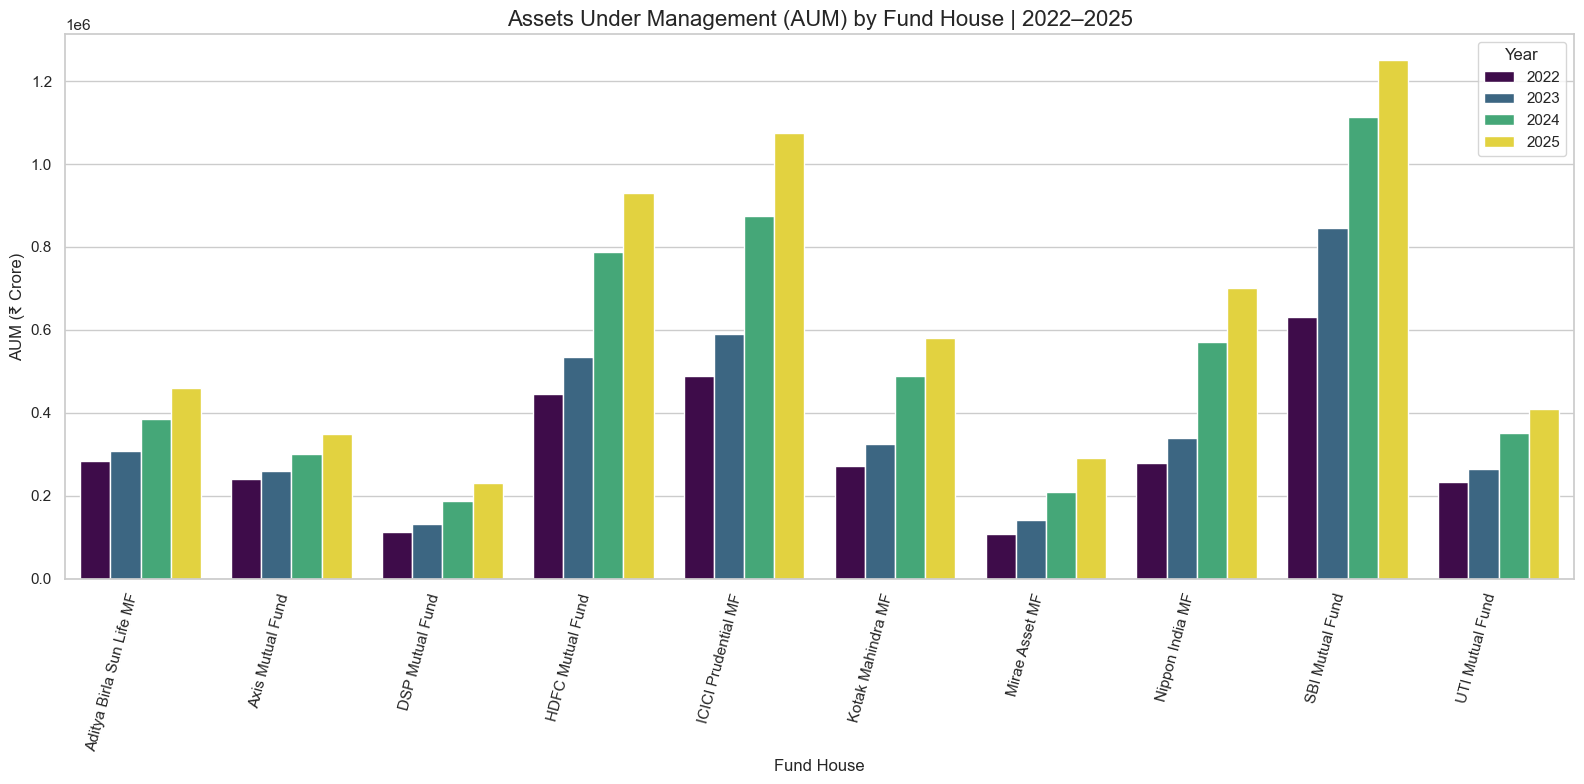

In [16]:
# Chart 2: Year-wise AUM by Fund House

plt.figure(figsize=(16, 8))

sns.barplot(
    data=aum_yearly,
    x="fund_house",
    y="aum_crore",
    hue="year",
    palette="viridis"
)

plt.title("Assets Under Management (AUM) by Fund House | 2022–2025", fontsize=16)
plt.xlabel("Fund House")
plt.ylabel("AUM (₹ Crore)")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Year")
plt.tight_layout()

plt.show()

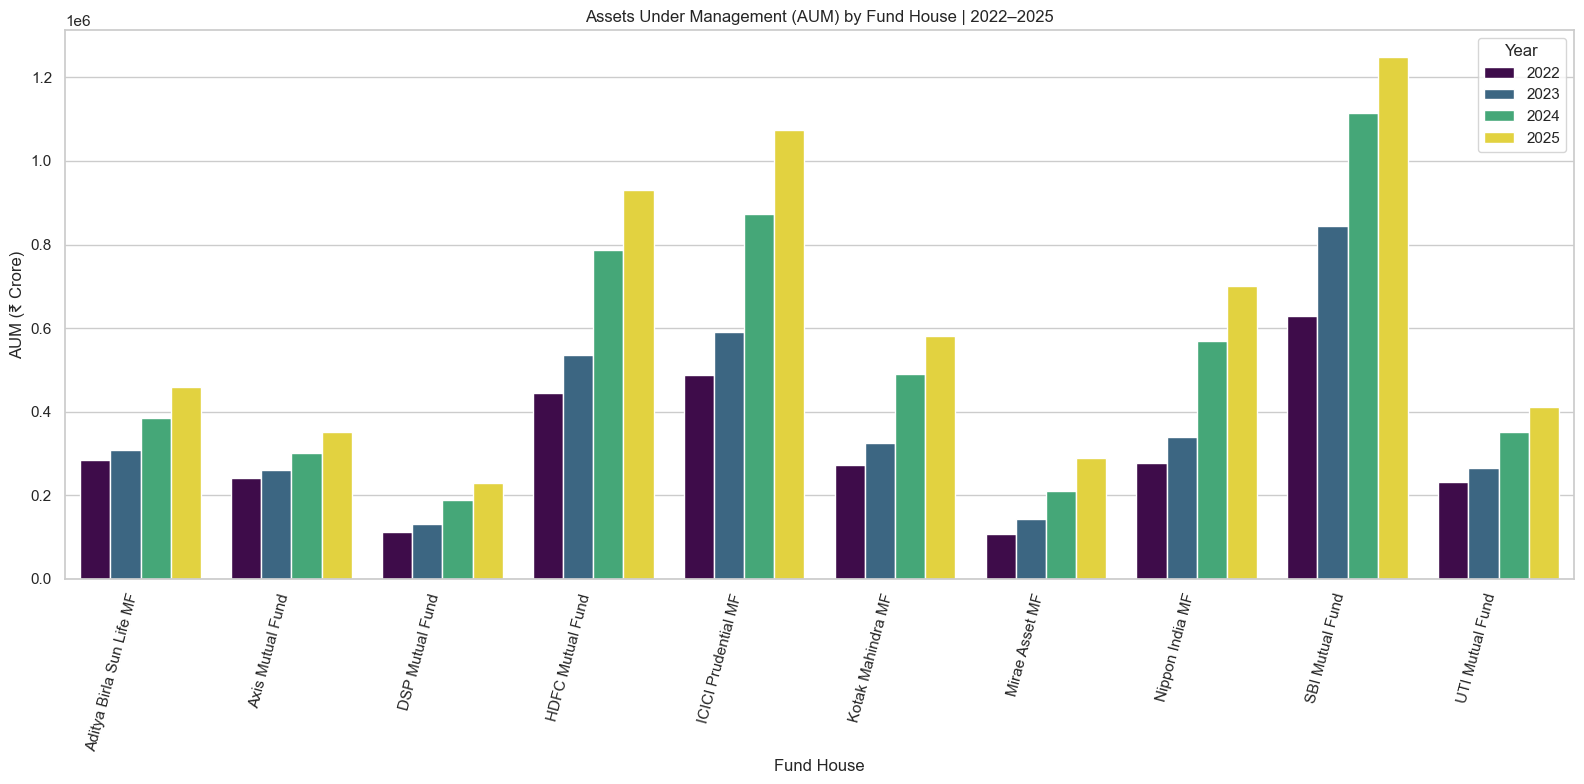


Top Fund Houses in 2025:


,fund_house,aum_crore
38,SBI Mutual Fund,1250000
34,ICICI Prudential MF,1074000
33,HDFC Mutual Fund,930000
37,Nippon India MF,700000
35,Kotak Mahindra MF,580000


In [17]:
# Save Chart 2 as PNG

chart2_path = charts_path / "chart02_aum_by_fund_house.png"

plt.figure(figsize=(16, 8))
sns.barplot(
    data=aum_yearly,
    x="fund_house",
    y="aum_crore",
    hue="year",
    palette="viridis"
)
plt.title("Assets Under Management (AUM) by Fund House | 2022–2025")
plt.xlabel("Fund House")
plt.ylabel("AUM (₹ Crore)")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig(chart2_path, dpi=300, bbox_inches="tight")
plt.show()

# Find largest fund house in latest year
latest_year = aum_yearly["year"].max()
latest_aum = aum_yearly[aum_yearly["year"] == latest_year].sort_values("aum_crore", ascending=False)

print(f"\nTop Fund Houses in {latest_year}:")
display(latest_aum[["fund_house", "aum_crore"]].head(5))

### EDA Finding #2 — Assets Under Management by Fund House

- Assets Under Management (AUM) vary considerably across fund houses, indicating differences in their overall scale and investor asset base.
- Year-wise comparison from 2022 to 2025 helps identify changes in fund-house size and asset growth over time.
- Larger AUM indicates a larger asset base managed, but does not alone indicate superior investment performance.
- **Chart Reference:** `chart02_aum_by_fund_house.png`


In [18]:
sip_df = pd.read_csv(processed_path / "monthly_sip_inflows_cleaned.csv")

sip_df["month"] = pd.to_datetime(sip_df["month"])
sip_df = sip_df.sort_values("month")

display(sip_df.head())
display(sip_df.tail())

,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01-01,11517,4.91,9.10,4.80,NaN
1,2022-02-01,11438,4.93,8.20,4.85,NaN
2,2022-03-01,12328,5.09,10.50,5.01,NaN
3,2022-04-01,11863,5.48,9.52,5.12,NaN
4,2022-05-01,12286,5.55,8.10,5.15,NaN


,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
43,2025-08-01,28265,8.85,9.80,15.18,20.04
44,2025-09-01,29361,9.00,10.50,15.38,19.80
45,2025-10-01,29529,9.10,9.45,15.55,16.61
46,2025-11-01,30200,9.20,9.10,15.72,19.27
47,2025-12-01,31002,9.35,9.80,15.90,17.17


In [19]:
# Find the peak SIP inflow month
peak_sip = sip_df.loc[sip_df["sip_inflow_crore"].idxmax()]

print("Peak SIP Inflow:")
print("Month:", peak_sip["month"].strftime("%B %Y"))
print("Amount: ₹", peak_sip["sip_inflow_crore"], "Crore")

# Create interactive chart
fig_sip = px.line(
    sip_df,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflows in India (2022–2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

# Highlight the peak month
fig_sip.add_trace(
    go.Scatter(
        x=[peak_sip["month"]],
        y=[peak_sip["sip_inflow_crore"]],
        mode="markers+text",
        marker=dict(size=14, color="red"),
        text=[f"Peak: ₹{peak_sip['sip_inflow_crore']:,.0f} Cr"],
        textposition="top center",
        name="Peak SIP"
    )
)

fig_sip.update_layout(
    template="plotly_white",
    height=600,
    hovermode="x unified"
)

fig_sip.show(renderer="browser")

Peak SIP Inflow:
Month: December 2025
Amount: ₹ 31002 Crore


In [2]:
# Save interactive HTML chart
fig_sip.write_html(charts_path / "chart03_monthly_sip_inflows.html")

# Save static PNG chart
fig_sip.write_image(
    charts_path / "chart03_monthly_sip_inflows.png",
    width=1400,
    height=700,
    scale=2
)

print("Chart 3 saved successfully!")

NameError: name 'fig_sip' is not defined

In [22]:
import sys
import kaleido

print("Python used by Notebook:", sys.executable)
print("Kaleido version:", kaleido.__version__)

Python used by Notebook: c:\Users\admin\AppData\Local\Programs\Python\Python312\python.exe


AttributeError: module 'kaleido' has no attribute '__version__'

In [23]:
import sys
print(sys.executable)

c:\Users\admin\AppData\Local\Programs\Python\Python312\python.exe


In [1]:
import importlib.metadata

print("Kaleido version:", importlib.metadata.version("kaleido"))

Kaleido version: 1.5.2


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

project_root = Path.cwd().parent
processed_path = project_root / "data" / "processed"
charts_path = project_root / "reports" / "charts"
charts_path.mkdir(parents=True, exist_ok=True)

sip_df = pd.read_csv(processed_path / "monthly_sip_inflows_cleaned.csv")
sip_df["month"] = pd.to_datetime(sip_df["month"])
sip_df = sip_df.sort_values("month")

print("SIP data restored:", len(sip_df), "rows")

SIP data restored: 48 rows


In [5]:
peak_sip = sip_df.loc[sip_df["sip_inflow_crore"].idxmax()]

fig_sip = px.line(
    sip_df,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflows in India (2022–2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

fig_sip.add_trace(
    go.Scatter(
        x=[peak_sip["month"]],
        y=[peak_sip["sip_inflow_crore"]],
        mode="markers+text",
        marker=dict(size=14, color="red"),
        text=[f"Peak: ₹{peak_sip['sip_inflow_crore']:,.0f} Cr"],
        textposition="top center",
        name="Peak SIP"
    )
)

fig_sip.update_layout(
    template="plotly_white",
    height=600,
    hovermode="x unified"
)

fig_sip.show(renderer="browser")

In [6]:
# Save interactive HTML
fig_sip.write_html(charts_path / "chart03_monthly_sip_inflows.html")

# Save PNG image
fig_sip.write_image(
    charts_path / "chart03_monthly_sip_inflows.png",
    width=1400,
    height=700,
    scale=2
)

print("Chart 3 saved successfully!")

Chart 3 saved successfully!


### EDA Finding #3 — Monthly SIP Inflows Growth

- Monthly Systematic Investment Plan (SIP) inflows show an overall increasing trend from January 2022 to December 2025.
- SIP inflows reached their highest observed value in **December 2025 at ₹31,002 crore**.
- The upward trend indicates increasing participation in systematic mutual fund investing over the analyzed period.
- **Chart Reference:** `chart03_monthly_sip_inflows.html` and `chart03_monthly_sip_inflows.png`


In [7]:
category_df = pd.read_csv(
    processed_path / "category_inflows_cleaned.csv"
)

category_df["month"] = pd.to_datetime(category_df["month"])

display(category_df.head(10))
print("Total rows:", len(category_df))
print("Categories:", category_df["category"].unique())
print("Date range:", category_df["month"].min(), "to", category_df["month"].max())

,month,category,net_inflow_crore
0,2024-04-01,Large Cap,2413.0
1,2024-04-01,Mid Cap,3897.0
2,2024-04-01,Small Cap,3533.0
3,2024-04-01,Flexi Cap,4947.0
4,2024-04-01,Large & Mid Cap,4214.0
5,2024-04-01,ELSS,466.0
6,2024-04-01,Value/Contra,1328.0
7,2024-04-01,Sectoral/Thematic,8052.0
8,2024-04-01,Liquid,37537.0
9,2024-04-01,Short Duration,4400.0


Total rows: 144
Categories: ['Large Cap' 'Mid Cap' 'Small Cap' 'Flexi Cap' 'Large & Mid Cap' 'ELSS'
 'Value/Contra' 'Sectoral/Thematic' 'Liquid' 'Short Duration' 'Gilt'
 'Hybrid']
Date range: 2024-04-01 00:00:00 to 2025-03-01 00:00:00


In [8]:
# Create month labels
category_df["month_label"] = category_df["month"].dt.strftime("%b %Y")

# Pivot data: Months as rows, categories as columns
category_pivot = category_df.pivot(
    index="month_label",
    columns="category",
    values="net_inflow_crore"
)

# Maintain chronological order
month_order = (
    category_df[["month", "month_label"]]
    .drop_duplicates()
    .sort_values("month")["month_label"]
)

category_pivot = category_pivot.reindex(month_order)

display(category_pivot)

category,ELSS,Flexi Cap,Gilt,Hybrid,Large & Mid Cap,Large Cap,Liquid,Mid Cap,Sectoral/Thematic,Short Duration,Small Cap,Value/Contra
month_label,,,,,,,,,,,,
Apr 2024,466.0,4947.0,784.0,2955.0,4214.0,2413.0,37537.0,3897.0,8052.0,4400.0,3533.0,1328.0
May 2024,553.0,5529.0,836.0,3487.0,4368.0,2076.0,41872.0,5300.0,8354.0,4833.0,4092.0,1361.0
Jun 2024,472.0,4478.0,864.0,3163.0,4610.0,2519.0,40486.0,5047.0,10030.0,4321.0,3535.0,1386.0
Jul 2024,471.0,4869.0,959.0,3291.0,5023.0,2574.0,34643.0,4548.0,9896.0,4170.0,3582.0,1582.0
Aug 2024,499.0,5562.0,952.0,3684.0,5411.0,1940.0,41952.0,3899.0,8360.0,4658.0,3376.0,1308.0
Sep 2024,537.0,5397.0,925.0,3015.0,4528.0,1879.0,35308.0,4960.0,8518.0,5327.0,4137.0,1334.0
Oct 2024,537.0,6004.0,898.0,3314.0,4581.0,2255.0,39091.0,4106.0,7680.0,4675.0,4444.0,1595.0
Nov 2024,571.0,6111.0,704.0,3264.0,5556.0,1870.0,40506.0,4336.0,7397.0,5316.0,3256.0,1436.0
Dec 2024,521.0,4654.0,831.0,3538.0,4878.0,1923.0,34933.0,5023.0,9820.0,4159.0,4249.0,1414.0


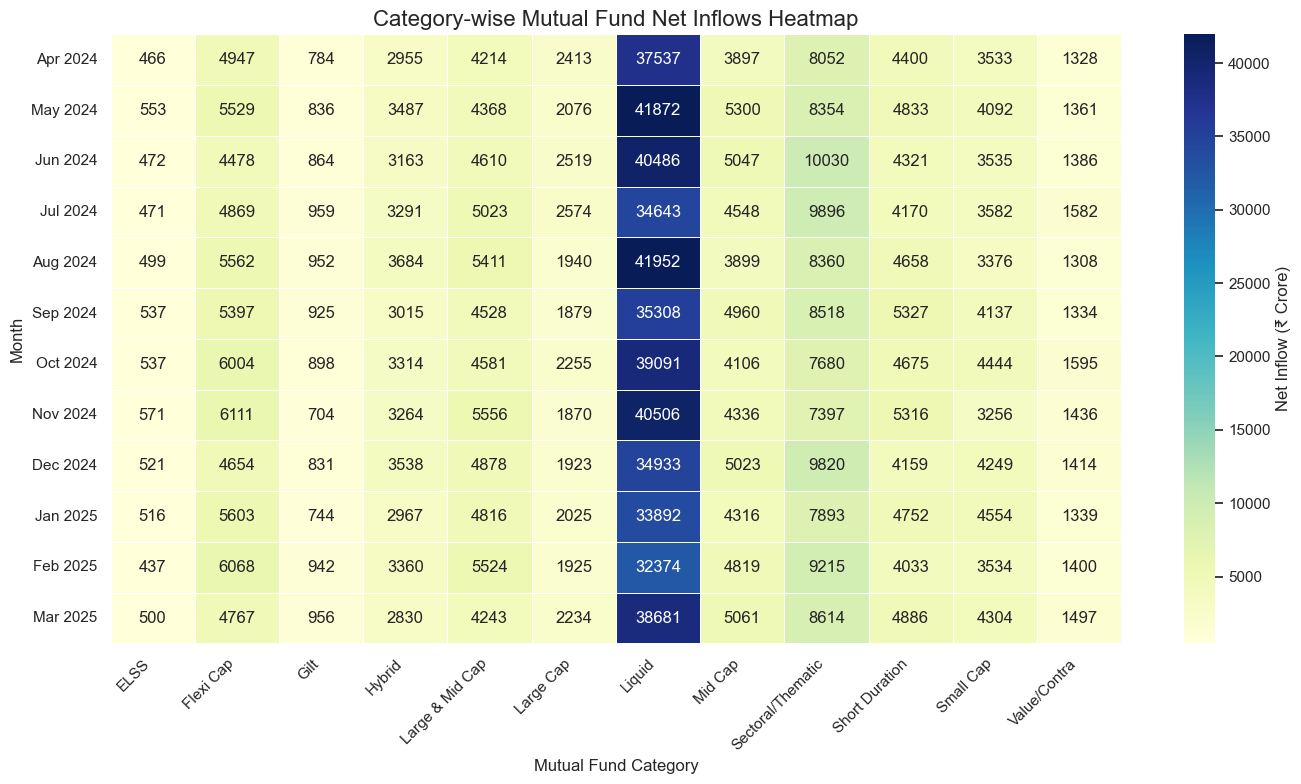

In [9]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    category_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Category-wise Mutual Fund Net Inflows Heatmap", fontsize=16)
plt.xlabel("Mutual Fund Category")
plt.ylabel("Month")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

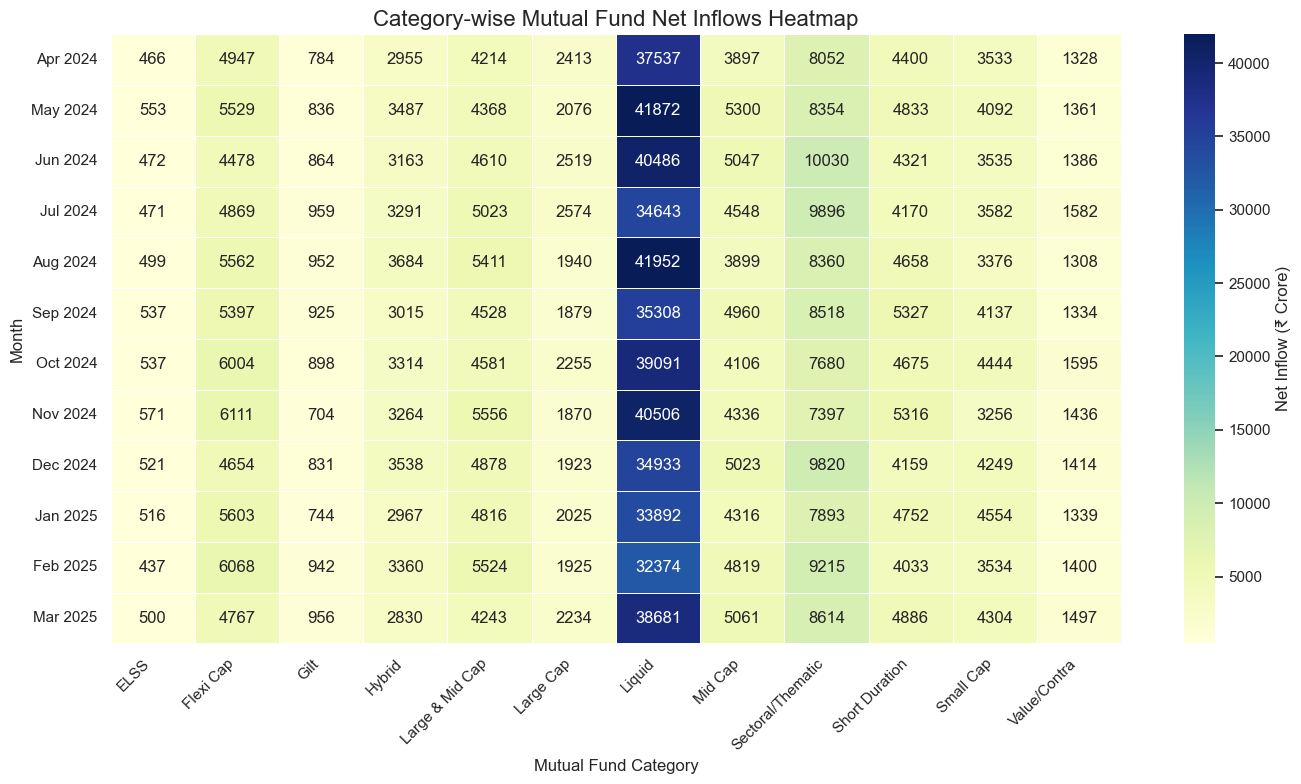

Chart 4 saved successfully!


In [10]:
# Save Category Inflow Heatmap
chart4_path = charts_path / "chart04_category_inflow_heatmap.png"

plt.figure(figsize=(14, 8))

sns.heatmap(
    category_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Category-wise Mutual Fund Net Inflows Heatmap", fontsize=16)
plt.xlabel("Mutual Fund Category")
plt.ylabel("Month")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(chart4_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart 4 saved successfully!")

### EDA Finding #4 — Category-wise Inflow Patterns

- Mutual fund net inflows vary across investment categories and months.
- The heatmap provides a visual comparison of monthly inflow patterns across categories during the available period (April 2024–March 2025).
- Differences in color intensity help identify relatively higher and lower inflow periods across categories.
- **Chart Reference:** `chart04_category_inflow_heatmap.png`


In [11]:
investor_df = pd.read_csv(
    processed_path / "investor_transactions_cleaned.csv"
)

print("Total transactions:", len(investor_df))
print("\nAge groups:")
print(investor_df["age_group"].value_counts())

display(investor_df.head())

Total transactions: 32778

Age groups:
age_group
26-35    13463
36-45     8146
18-25     4916
46-55     3779
56+       2474
Name: count, dtype: int64


,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,VERIFIED
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,VERIFIED
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,VERIFIED
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,PENDING
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,PENDING


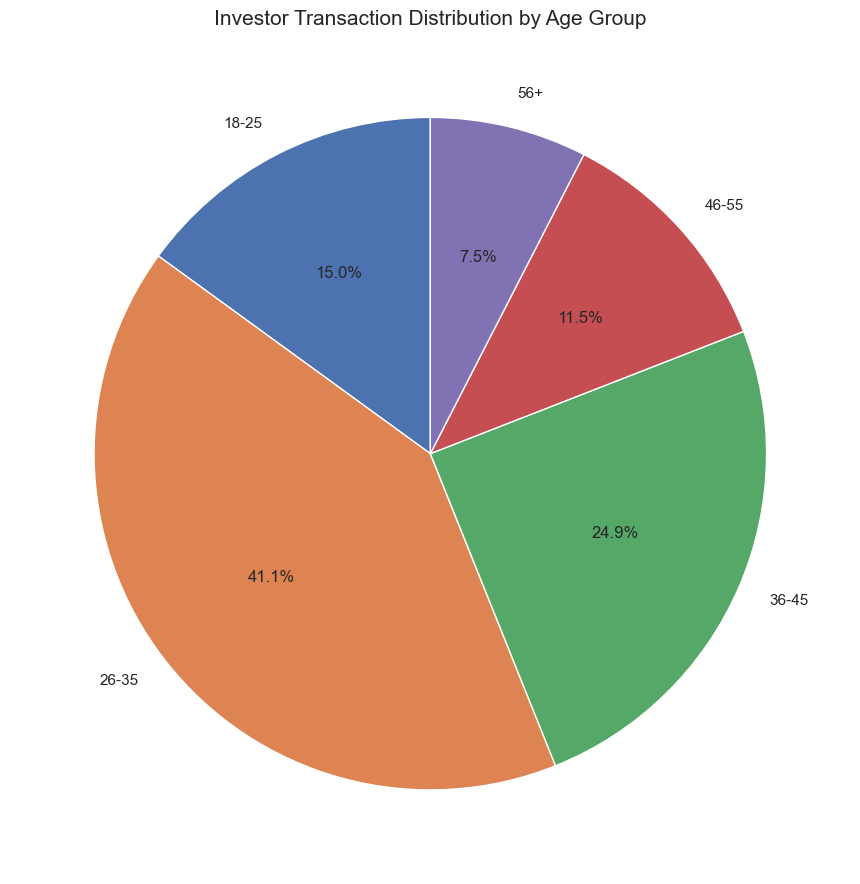

In [12]:
# Count investors by age group
age_counts = investor_df["age_group"].value_counts().sort_index()

plt.figure(figsize=(9, 9))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Investor Transaction Distribution by Age Group", fontsize=15)
plt.tight_layout()
plt.show()

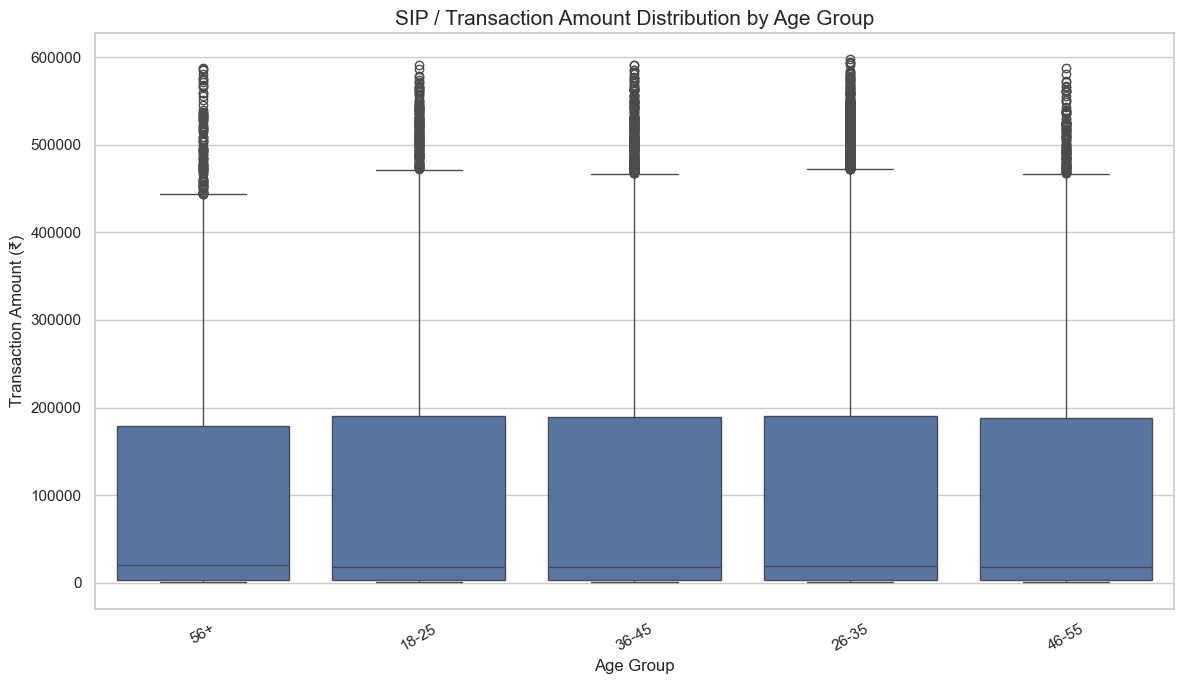

In [13]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=investor_df,
    x="age_group",
    y="amount_inr"
)

plt.title("SIP / Transaction Amount Distribution by Age Group", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Transaction Amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

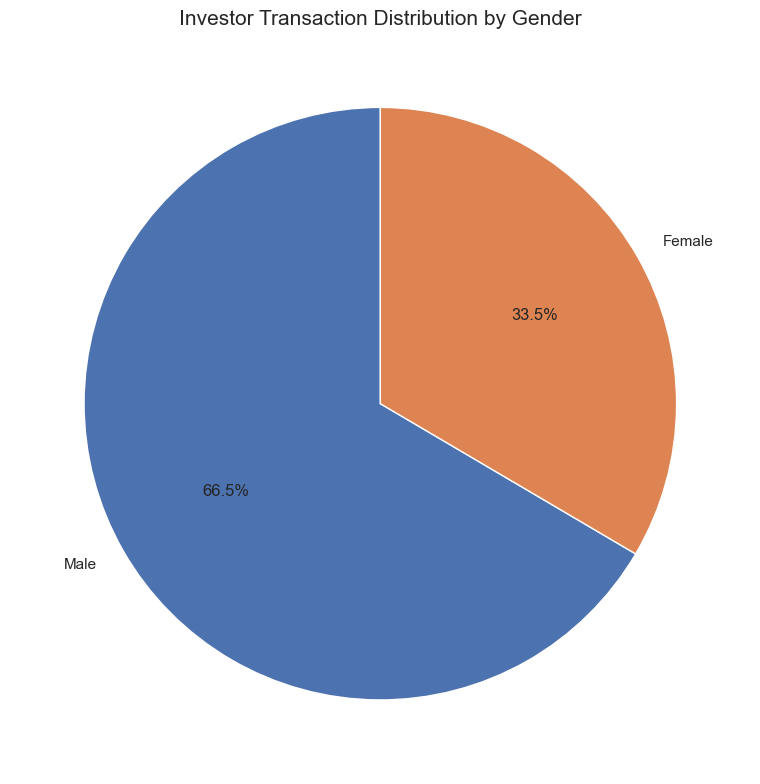

Gender-wise transaction counts:


gender
Male      21809
Female    10969
Name: count, dtype: int64

In [14]:
gender_counts = investor_df["gender"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Investor Transaction Distribution by Gender", fontsize=15)
plt.tight_layout()
plt.show()

print("Gender-wise transaction counts:")
display(gender_counts)

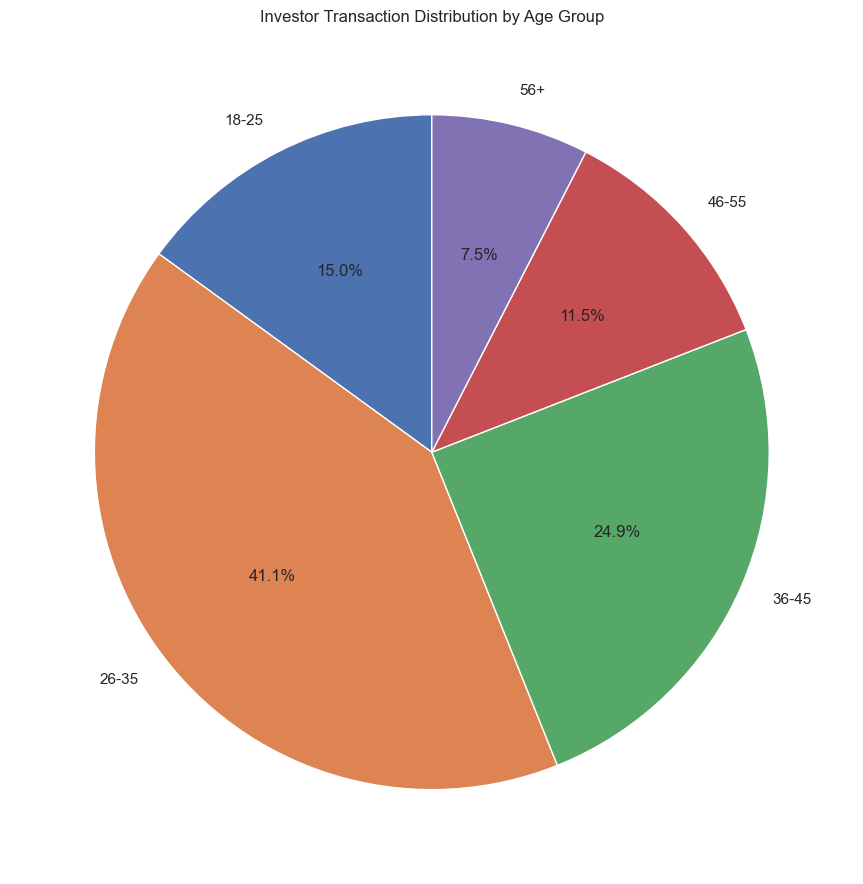

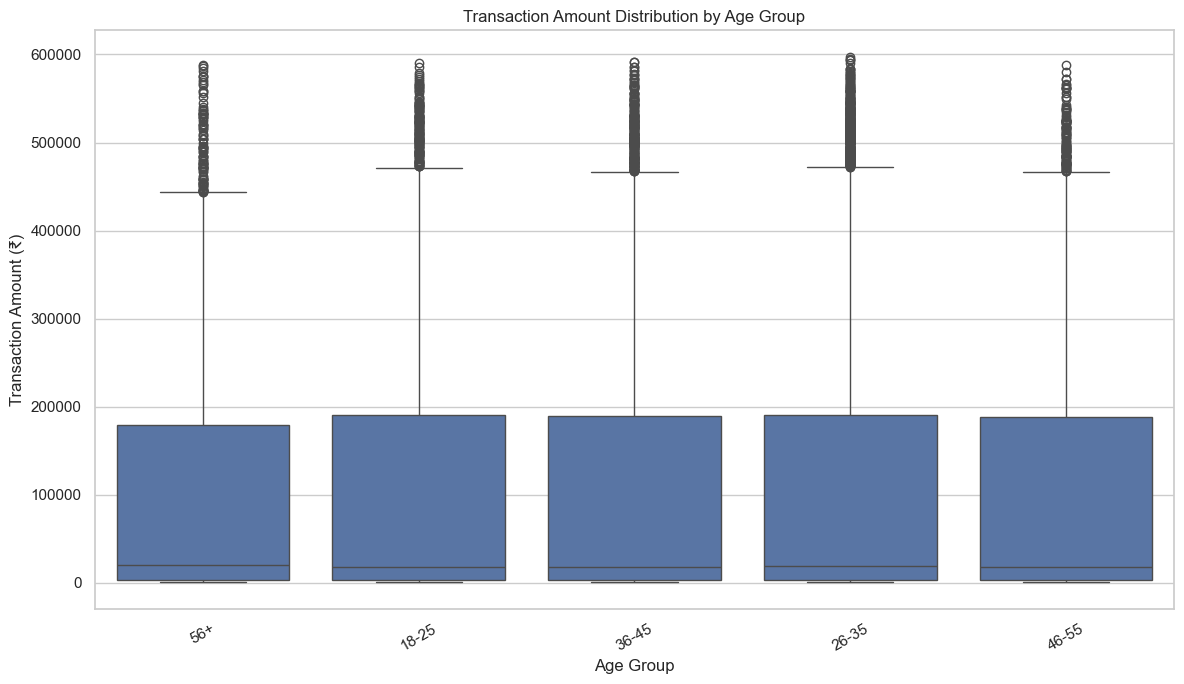

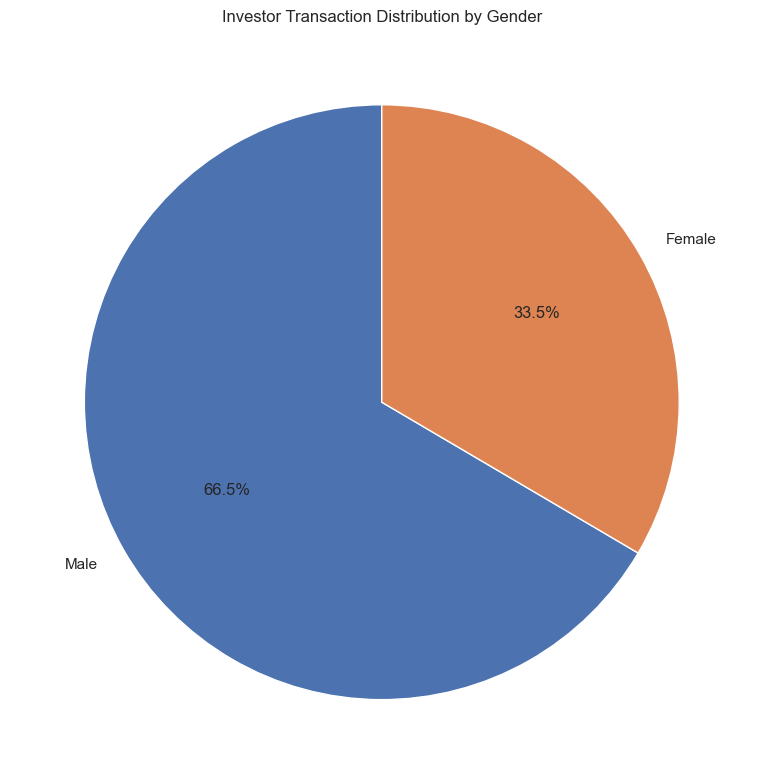

Charts 5, 6 and 7 saved successfully!


In [15]:
# Chart 5A — Age Distribution
plt.figure(figsize=(9, 9))
plt.pie(age_counts, labels=age_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Investor Transaction Distribution by Age Group")
plt.tight_layout()
plt.savefig(charts_path / "chart05_age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Chart 5B — Transaction Amount by Age Group
plt.figure(figsize=(12, 7))
sns.boxplot(data=investor_df, x="age_group", y="amount_inr")
plt.title("Transaction Amount Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Transaction Amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(charts_path / "chart06_amount_by_age_group.png", dpi=300, bbox_inches="tight")
plt.show()

# Chart 5C — Gender Distribution
plt.figure(figsize=(8, 8))
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Investor Transaction Distribution by Gender")
plt.tight_layout()
plt.savefig(charts_path / "chart07_gender_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Charts 5, 6 and 7 saved successfully!")

### EDA Finding #5 — Investor Demographics

- The investor transaction dataset contains different age groups, allowing demographic analysis of participation.
- The age distribution pie chart compares the representation of different age groups in the dataset.
- The age-wise transaction amount boxplot highlights differences in transaction values, spread, and potential outliers.
- Gender distribution provides a comparison of transaction representation across gender groups.
- **Chart References:**
  - `chart05_age_distribution.png`
  - `chart06_amount_by_age_group.png`
  - `chart07_gender_distribution.png`


In [16]:
print("Transaction Types:")
display(investor_df["transaction_type"].value_counts())

print("\nState count:", investor_df["state"].nunique())
print("\nStates:")
display(investor_df["state"].unique())

Transaction Types:


transaction_type
SIP           19716
Lumpsum        8095
Redemption     4967
Name: count, dtype: int64


State count: 12

States:


array(['Telangana', 'Punjab', 'Haryana', 'Maharashtra', 'Delhi',
       'Madhya Pradesh', 'Gujarat', 'Rajasthan', 'Uttar Pradesh',
       'Karnataka', 'West Bengal', 'Tamil Nadu'], dtype=object)

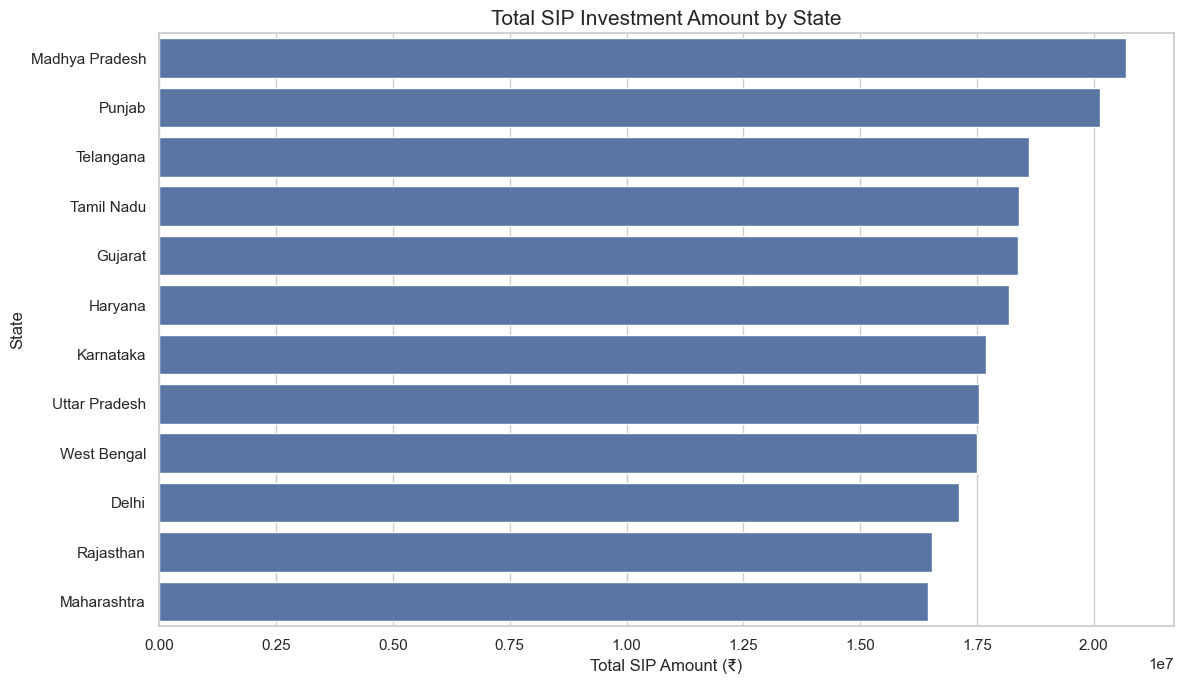

state
Madhya Pradesh    20682243
Punjab            20140064
Telangana         18620216
Tamil Nadu        18404368
Gujarat           18378904
Haryana           18176696
Karnataka         17696903
Uttar Pradesh     17534858
West Bengal       17495769
Delhi             17113608
Rajasthan         16544233
Maharashtra       16445629
Name: amount_inr, dtype: int64

In [17]:
# Filter only SIP transactions
sip_transactions = investor_df[
    investor_df["transaction_type"] == "SIP"
]

# Aggregate SIP amount by state
state_sip = (
    sip_transactions.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
)

# Plot
plt.figure(figsize=(12, 7))

sns.barplot(
    x=state_sip.values,
    y=state_sip.index,
    orient="h"
)

plt.title("Total SIP Investment Amount by State", fontsize=15)
plt.xlabel("Total SIP Amount (₹)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

display(state_sip)

In [18]:
print("City Tier Distribution:")
display(investor_df["city_tier"].value_counts())

print("\nUnique city tiers:")
display(investor_df["city_tier"].unique())

City Tier Distribution:


city_tier
T30    21719
B30    11059
Name: count, dtype: int64


Unique city tiers:


array(['T30', 'B30'], dtype=object)

SIP Transactions by City Tier:


city_tier
T30    13123
B30     6593
Name: count, dtype: int64

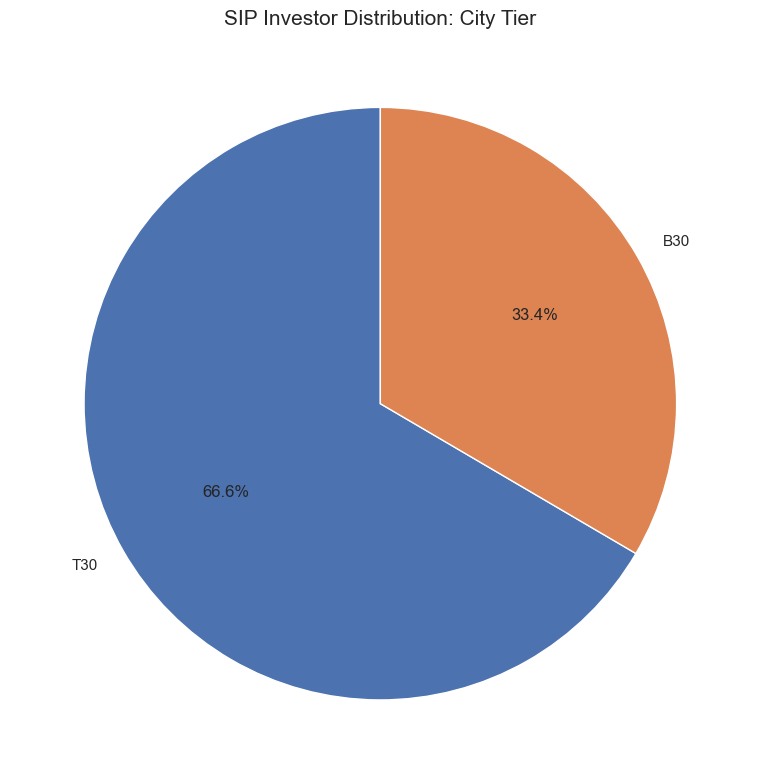

In [19]:
# Count SIP transactions by city tier
tier_counts = sip_transactions["city_tier"].value_counts()

print("SIP Transactions by City Tier:")
display(tier_counts)

# Pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    tier_counts,
    labels=tier_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("SIP Investor Distribution: City Tier", fontsize=15)
plt.tight_layout()
plt.show()

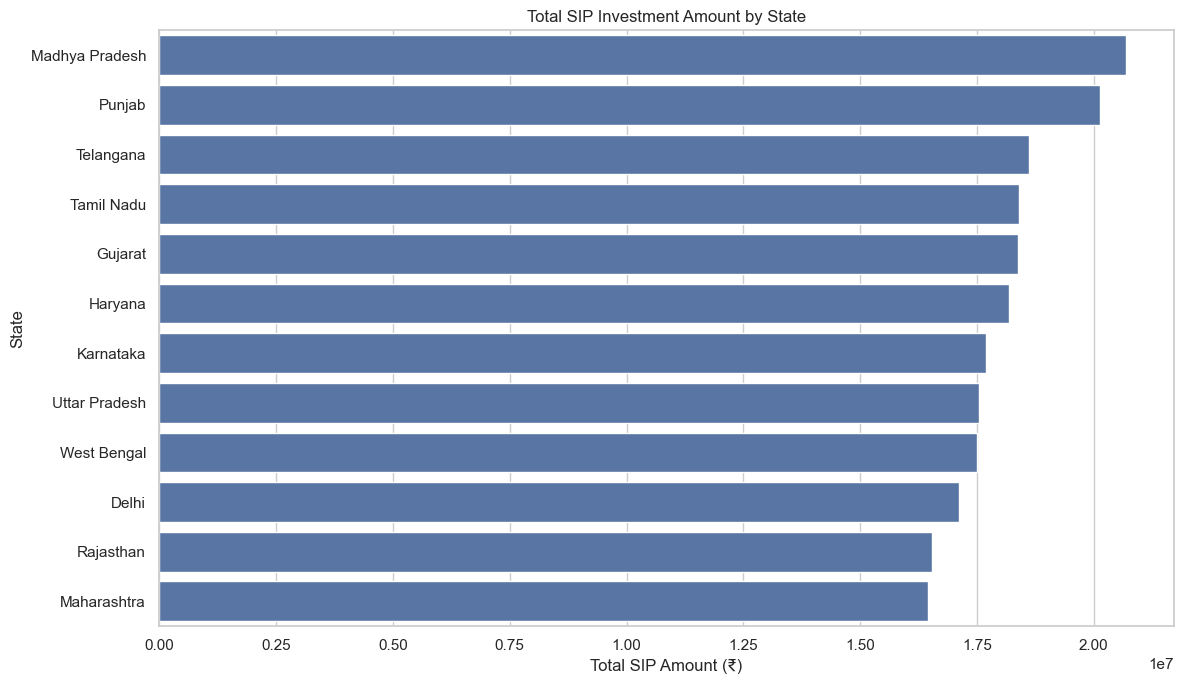

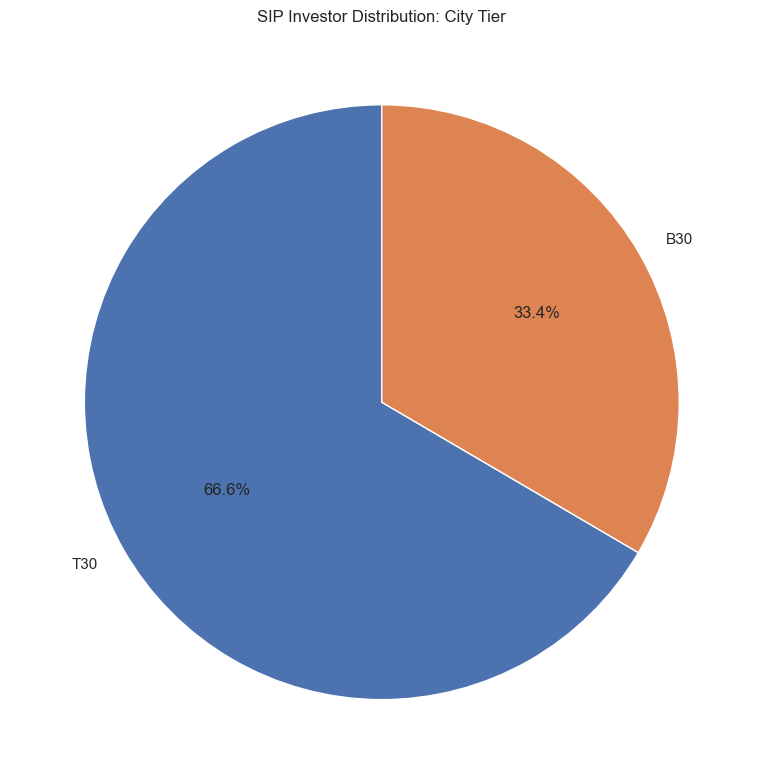

Charts 8 and 9 saved successfully!


In [20]:
# Chart 8 — State-wise SIP Investment
plt.figure(figsize=(12, 7))
sns.barplot(x=state_sip.values, y=state_sip.index, orient="h")
plt.title("Total SIP Investment Amount by State")
plt.xlabel("Total SIP Amount (₹)")
plt.ylabel("State")
plt.tight_layout()
plt.savefig(charts_path / "chart08_statewise_sip.png", dpi=300, bbox_inches="tight")
plt.show()

# Chart 9 — City Tier Distribution
plt.figure(figsize=(8, 8))
plt.pie(tier_counts, labels=tier_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("SIP Investor Distribution: City Tier")
plt.tight_layout()
plt.savefig(charts_path / "chart09_city_tier_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Charts 8 and 9 saved successfully!")

### EDA Finding #6 — Geographic Investment Patterns

- SIP transaction amounts differ across the states represented in the dataset.
- The state-wise SIP bar chart compares total recorded SIP transaction values across 12 states.
- City-tier distribution compares SIP transaction representation between the recorded tier groups, helping explore participation from different city segments.
- Geographic results reflect the transactions available in the dataset and may not represent the entire Indian mutual fund market.
- **Chart References:**
  - `chart08_statewise_sip.png`
  - `chart09_city_tier_distribution.png`


In [21]:
folio_df = pd.read_csv(
    processed_path / "industry_folio_count_cleaned.csv"
)

folio_df["month"] = pd.to_datetime(folio_df["month"])
folio_df = folio_df.sort_values("month")

display(folio_df.head())
display(folio_df.tail())

print("Total records:", len(folio_df))

,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01-01,13.26,9.28,1.86,0.80,1.33
1,2022-04-01,13.91,9.74,1.95,0.83,1.39
2,2022-07-01,13.85,9.69,1.94,0.83,1.38
3,2022-10-01,14.12,9.88,1.98,0.85,1.41
4,2023-01-01,14.81,10.37,2.07,0.89,1.48


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
16,2025-07-01,24.57,17.20,3.44,1.47,2.46
17,2025-08-01,24.89,17.42,3.48,1.49,2.49
18,2025-09-01,25.19,17.63,3.53,1.51,2.52
19,2025-10-01,25.60,17.92,3.58,1.54,2.56
20,2025-12-01,26.12,18.28,3.66,1.57,2.61


Total records: 21


In [23]:
plt.figure(figsize=(14, 7))

plt.plot(
    folio_df["month"],
    folio_df["total_folios_crore"],
    marker="o",
    linewidth=2
)

plt.title("Mutual Fund Folio Growth in India (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid(True, alpha=0.3)

# First and last values
first_row = folio_df.iloc[0]
last_row = folio_df.iloc[-1]

# Starting value annotation
plt.annotate(
    f"Start: {first_row['total_folios_crore"]:.2f} Cr",
    xy=(first_row["month"], first_row["total_folios_crore"]),
    xytext=(15, 15),
    textcoords="offset points"
)

# Ending value annotation
plt.annotate(
    f"End: {last_row["total_folios_crore"]:.2f} Cr",
    xy=(last_row["month"], last_row["total_folios_crore"]),
    xytext=(-90, 15),
    textcoords="offset points"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Starting Folios:", first_row["total_folios_crore"], "Cr")
print("Ending Folios:", last_row["total_folios_crore"], "Cr")

SyntaxError: unterminated string literal (detected at line 21) (2427310339.py, line 21)

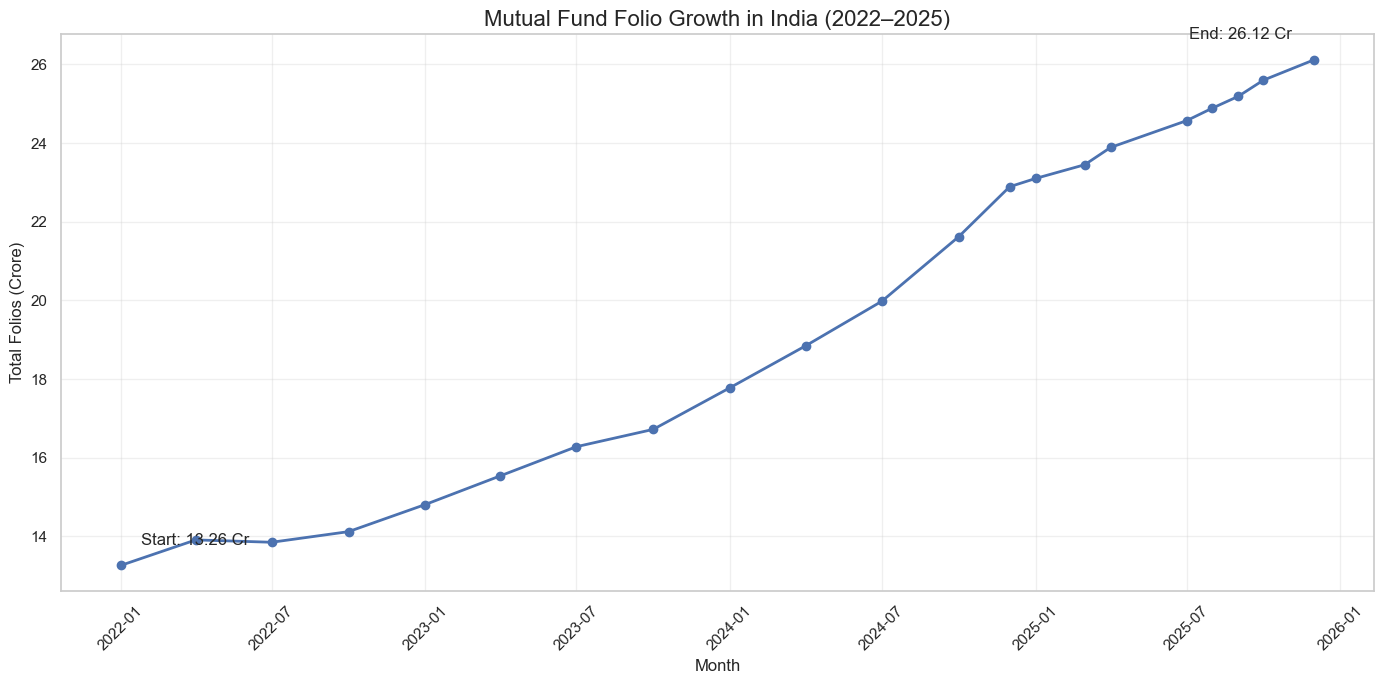

Starting Folios: 13.26 Cr
Ending Folios: 26.12 Cr


In [24]:
plt.figure(figsize=(14, 7))

plt.plot(
    folio_df["month"],
    folio_df["total_folios_crore"],
    marker="o",
    linewidth=2
)

plt.title("Mutual Fund Folio Growth in India (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid(True, alpha=0.3)

first_row = folio_df.iloc[0]
last_row = folio_df.iloc[-1]

start_value = first_row["total_folios_crore"]
end_value = last_row["total_folios_crore"]

plt.annotate(
    "Start: " + str(round(start_value, 2)) + " Cr",
    (first_row["month"], start_value),
    xytext=(15, 15),
    textcoords="offset points"
)

plt.annotate(
    "End: " + str(round(end_value, 2)) + " Cr",
    (last_row["month"], end_value),
    xytext=(-90, 15),
    textcoords="offset points"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Starting Folios:", round(start_value, 2), "Cr")
print("Ending Folios:", round(end_value, 2), "Cr")

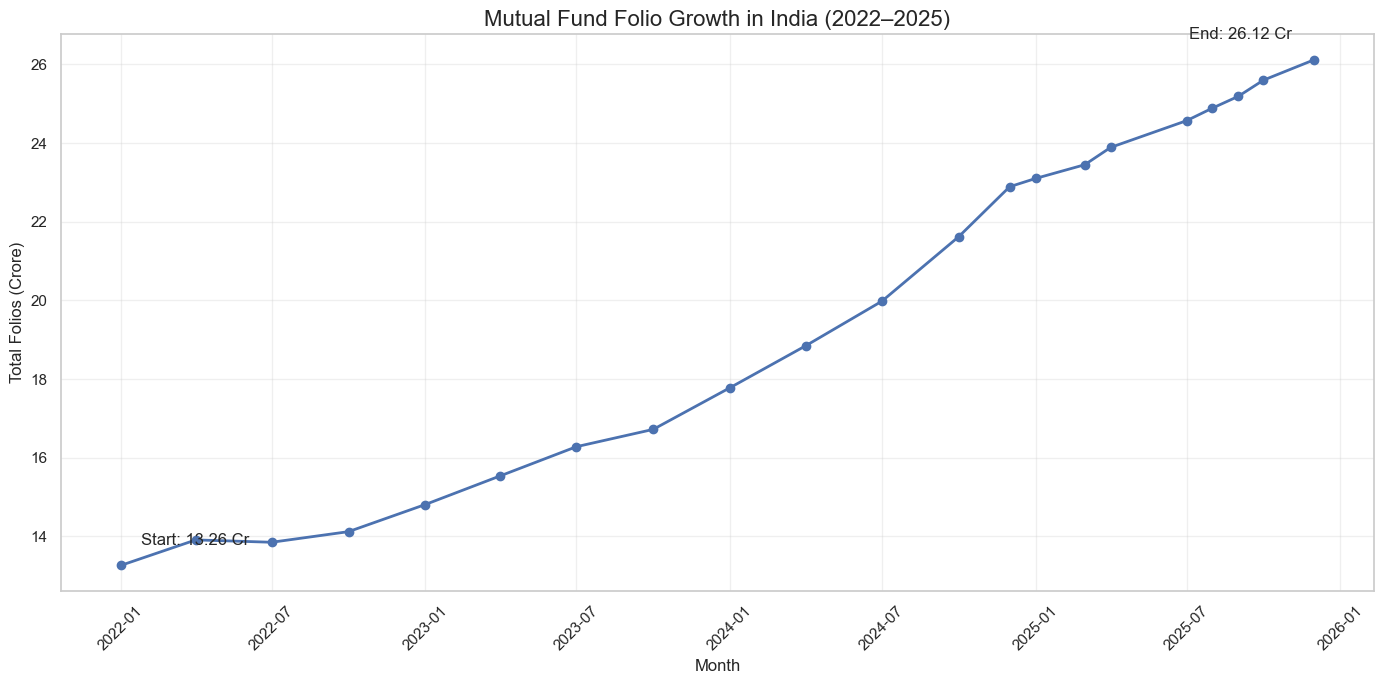

Chart 10 saved successfully!
Start: 13.26 Cr
End: 26.12 Cr


In [25]:
plt.figure(figsize=(14, 7))

plt.plot(
    folio_df["month"],
    folio_df["total_folios_crore"],
    marker="o",
    linewidth=2
)

plt.title("Mutual Fund Folio Growth in India (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid(True, alpha=0.3)

first_row = folio_df.iloc[0]
last_row = folio_df.iloc[-1]

start_value = first_row["total_folios_crore"]
end_value = last_row["total_folios_crore"]

plt.annotate(
    "Start: " + str(round(start_value, 2)) + " Cr",
    (first_row["month"], start_value),
    xytext=(15, 15),
    textcoords="offset points"
)

plt.annotate(
    "End: " + str(round(end_value, 2)) + " Cr",
    (last_row["month"], end_value),
    xytext=(-90, 15),
    textcoords="offset points"
)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    charts_path / "chart10_folio_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 10 saved successfully!")
print("Start:", round(start_value, 2), "Cr")
print("End:", round(end_value, 2), "Cr")

### EDA Finding #7 — Mutual Fund Folio Growth

- The folio dataset tracks the monthly growth of mutual fund investor accounts over the analyzed period.
- The line chart provides a view of how total folios change from January 2022 through December 2025.
- Comparing the beginning and ending values helps quantify the growth in folio accounts over the period.
- **Chart Reference:** `chart10_folio_growth.png`


In [26]:
scheme_list = fund_df[["amfi_code", "scheme_name"]].drop_duplicates()

display(scheme_list.head(20))
print("Total schemes:", len(scheme_list))

NameError: name 'fund_df' is not defined

In [27]:
fund_df = pd.read_csv(processed_path / "fund_master_cleaned.csv")

display(fund_df.head())
print("Total schemes:", len(fund_df))

,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,119551,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2006-02-14,NIFTY 100 TRI,1.54,1.0,500,1000,Sohini Andani,Moderate,EC01
1,119552,SBI Mutual Fund,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap,Direct,2013-01-01,NIFTY 100 TRI,0.66,1.0,500,1000,Sohini Andani,Moderate,EC01
2,119598,SBI Mutual Fund,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular,2009-09-09,BSE 250 SmallCap TRI,1.43,1.0,500,1000,R. Srinivasan,Very High,EC03
3,119599,SBI Mutual Fund,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap,Direct,2013-01-01,BSE 250 SmallCap TRI,0.72,1.0,500,1000,R. Srinivasan,Very High,EC03
4,119120,SBI Mutual Fund,SBI Magnum Gilt Fund - Regular Plan - Growth,Debt,Gilt,Regular,2000-12-30,CRISIL Dynamic Gilt Index,0.77,0.0,500,1000,Dinesh Ahuja,Low,DC02


Total schemes: 40


In [28]:
scheme_list = fund_df[["amfi_code", "scheme_name"]].drop_duplicates()

display(scheme_list.head(20))
print("Total schemes:", len(scheme_list))

,amfi_code,scheme_name
0,119551,SBI Bluechip Fund - Regular Plan - Growth
1,119552,SBI Bluechip Fund - Direct Plan - Growth
2,119598,SBI Small Cap Fund - Regular Plan - Growth
3,119599,SBI Small Cap Fund - Direct Plan - Growth
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth
5,100016,HDFC Top 100 Fund - Regular Plan - Growth
6,125497,HDFC Top 100 Fund - Direct Plan - Growth
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...
8,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth
9,100025,HDFC Short Term Debt Fund - Regular - Growth


Total schemes: 40


In [29]:
selected_codes = scheme_list["amfi_code"].drop_duplicates().head(10).tolist()

selected_schemes = scheme_list[
    scheme_list["amfi_code"].isin(selected_codes)
]

display(selected_schemes)

,amfi_code,scheme_name
0,119551,SBI Bluechip Fund - Regular Plan - Growth
1,119552,SBI Bluechip Fund - Direct Plan - Growth
2,119598,SBI Small Cap Fund - Regular Plan - Growth
3,119599,SBI Small Cap Fund - Direct Plan - Growth
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth
5,100016,HDFC Top 100 Fund - Regular Plan - Growth
6,125497,HDFC Top 100 Fund - Direct Plan - Growth
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...
8,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth
9,100025,HDFC Short Term Debt Fund - Regular - Growth


In [30]:
nav_df = pd.read_csv(processed_path / "nav_history_cleaned.csv")

nav_df["date"] = pd.to_datetime(nav_df["date"])
nav_df["amfi_code"] = nav_df["amfi_code"].astype(str)
selected_codes = [str(code) for code in selected_codes]

nav_10 = nav_df[nav_df["amfi_code"].isin(selected_codes)].copy()

print("Filtered NAV records:", len(nav_10))
print("Selected schemes:", nav_10["amfi_code"].nunique())
display(nav_10.head())

Filtered NAV records: 11500
Selected schemes: 10


,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [31]:
nav_pivot = nav_10.pivot(
    index="date",
    columns="amfi_code",
    values="nav"
)

daily_returns = nav_pivot.pct_change()

display(daily_returns.head(10))

amfi_code,100016,100025,100033,119120,119551,119552,119598,119599,125497,125498
date,,,,,,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-04,-0.010306,-0.003553,-0.013328,0.002651,-0.000702,-0.018306,-0.014735,-0.018716,0.001001,-0.005010
2022-01-05,0.012865,-0.000050,-0.004386,0.004416,0.006247,-0.005106,-0.005161,-0.001137,0.004250,-0.005184
2022-01-06,-0.011377,-0.001880,-0.005167,0.003598,0.014045,-0.011091,0.004824,-0.007924,-0.003589,-0.002706
2022-01-07,-0.001210,0.002036,-0.005748,-0.002465,-0.001547,0.015111,0.032830,-0.044252,-0.002719,-0.012660
2022-01-10,-0.008639,0.006791,0.006277,-0.000353,-0.001548,0.009465,0.051113,0.033761,0.003057,-0.019536
2022-01-11,0.005562,0.001545,0.001622,-0.000584,0.014549,-0.005536,0.010483,0.018183,-0.009703,0.013361
2022-01-12,-0.002404,-0.004719,-0.002770,0.001520,0.007310,0.020589,-0.002010,-0.005039,-0.002638,-0.021157
2022-01-13,-0.004050,-0.000623,0.002869,0.002018,-0.003618,0.009216,0.009334,0.001170,-0.007040,0.003641


In [32]:
correlation_matrix = daily_returns.corr()

display(correlation_matrix.round(2))

amfi_code,100016,100025,100033,119120,119551,119552,119598,119599,125497,125498
amfi_code,,,,,,,,,,
100016,1.00,0.05,-0.00,-0.02,0.04,0.01,-0.03,-0.00,0.05,-0.02
100025,0.05,1.00,0.00,-0.04,0.02,-0.00,-0.07,-0.03,0.01,-0.03
100033,-0.00,0.00,1.00,-0.01,-0.02,-0.03,0.01,-0.03,-0.03,-0.01
119120,-0.02,-0.04,-0.01,1.00,0.02,-0.00,0.02,0.02,-0.01,-0.02
119551,0.04,0.02,-0.02,0.02,1.00,-0.01,0.02,-0.07,0.02,0.03
119552,0.01,-0.00,-0.03,-0.00,-0.01,1.00,0.02,-0.04,0.03,-0.05
119598,-0.03,-0.07,0.01,0.02,0.02,0.02,1.00,0.02,-0.05,0.02
119599,-0.00,-0.03,-0.03,0.02,-0.07,-0.04,0.02,1.00,0.00,0.04
125497,0.05,0.01,-0.03,-0.01,0.02,0.03,-0.05,0.00,1.00,0.03


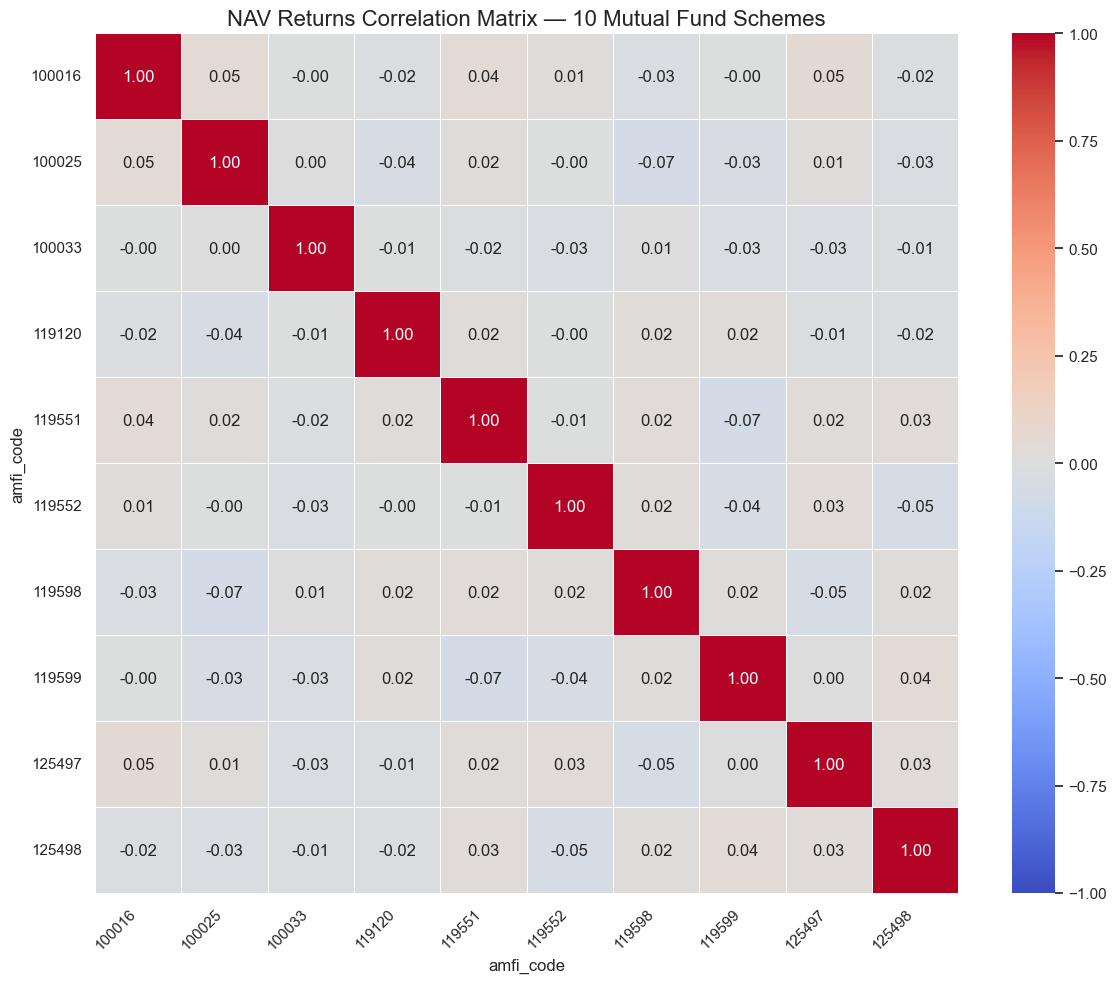

In [33]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("NAV Returns Correlation Matrix — 10 Mutual Fund Schemes", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

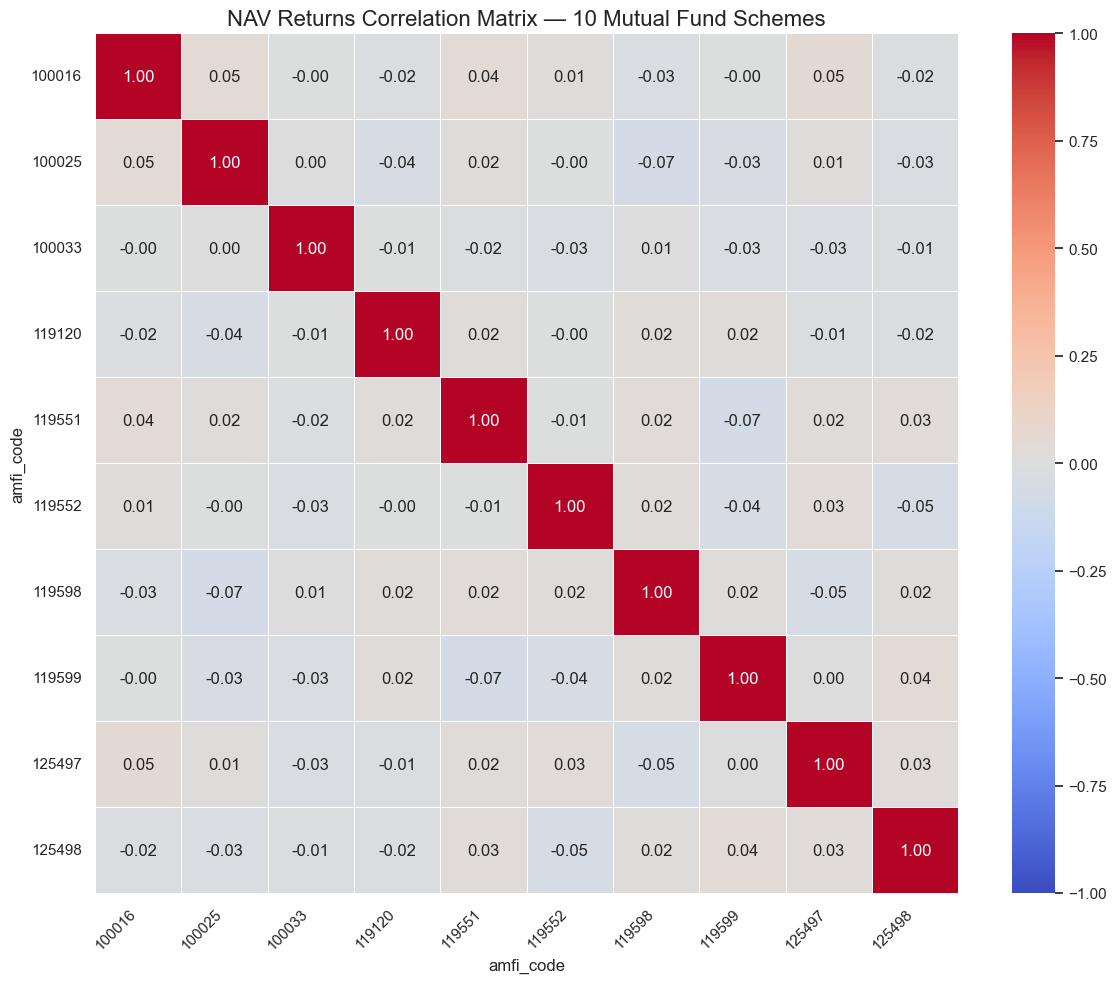

Chart 11 saved successfully!


In [34]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("NAV Returns Correlation Matrix — 10 Mutual Fund Schemes", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    charts_path / "chart11_nav_returns_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 11 saved successfully!")

### EDA Finding #8 — NAV Returns Correlation Across Mutual Fund Schemes

- The correlation heatmap compares daily NAV returns across 10 selected mutual fund schemes.
- Highly positive correlation indicates schemes tend to move in similar directions.
- Lower correlation may indicate potential diversification benefits.
- Correlation alone does not guarantee risk reduction or future performance.
- Chart Reference: chart11_nav_returns_correlation.png

In [35]:
holdings_df = pd.read_csv(
    processed_path / "portfolio_holdings_cleaned.csv"
)

display(holdings_df.head())
print("Total records:", len(holdings_df))
print("\nColumns:")
print(holdings_df.columns.tolist())
print("\nAvailable sectors:")
display(holdings_df["sector"].unique())

,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31


Total records: 322

Columns:
['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']

Available sectors:


array(['Utilities', 'Banking', 'Diversified', 'Pharma', 'Paints',
       'Telecom', 'IT', 'Automobile', 'NBFC', 'Cement', 'Energy',
       'Consumer Goods', 'FMCG', 'Infrastructure'], dtype=object)

In [36]:
sector_allocation = (
    holdings_df.groupby("sector")["weight_pct"]
    .mean()
    .sort_values(ascending=False)
)

display(sector_allocation)

sector
Consumer Goods    14.178889
Diversified       12.087857
IT                11.386750
Utilities         11.064167
FMCG              10.910000
Banking           10.871000
NBFC              10.826364
Pharma            10.722368
Automobile         9.807576
Telecom            9.708000
Energy             9.070000
Paints             8.986000
Cement             8.752500
Infrastructure     8.734545
Name: weight_pct, dtype: float64

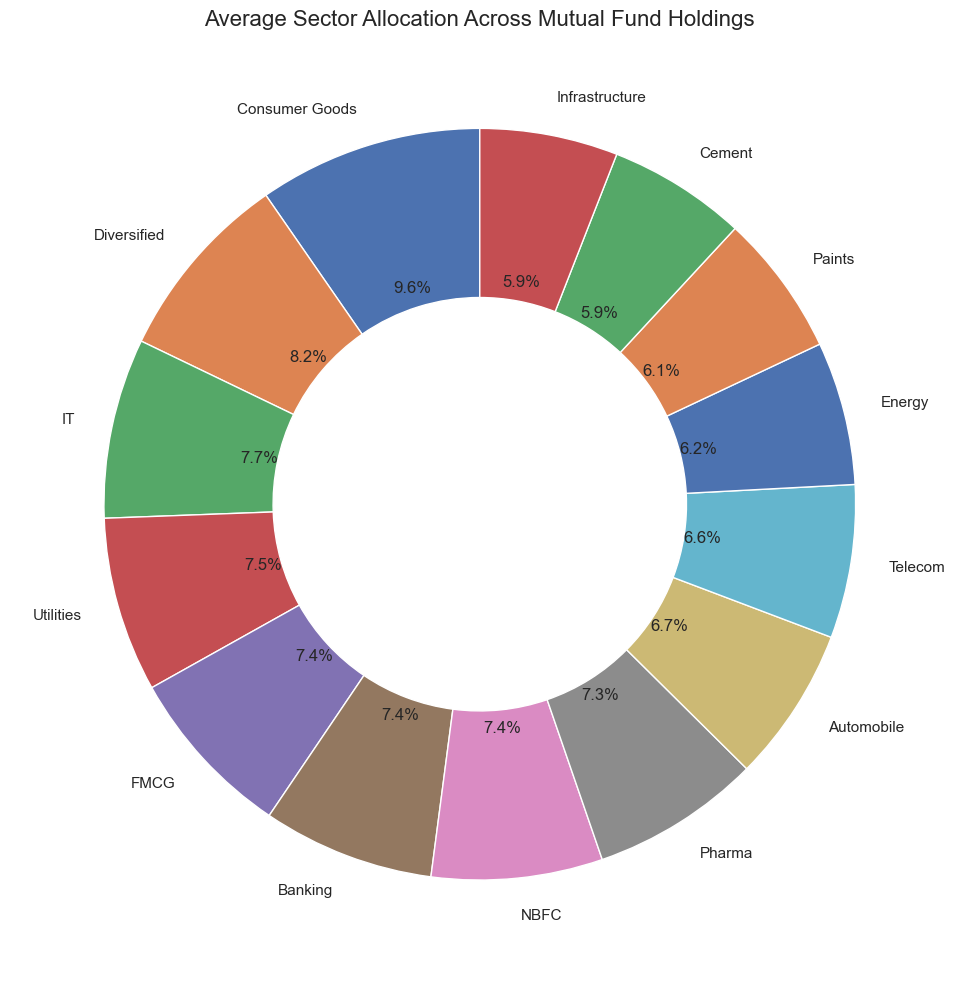

In [37]:
plt.figure(figsize=(10, 10))

plt.pie(
    sector_allocation,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)

plt.title("Average Sector Allocation Across Mutual Fund Holdings", fontsize=16)
plt.tight_layout()
plt.show()

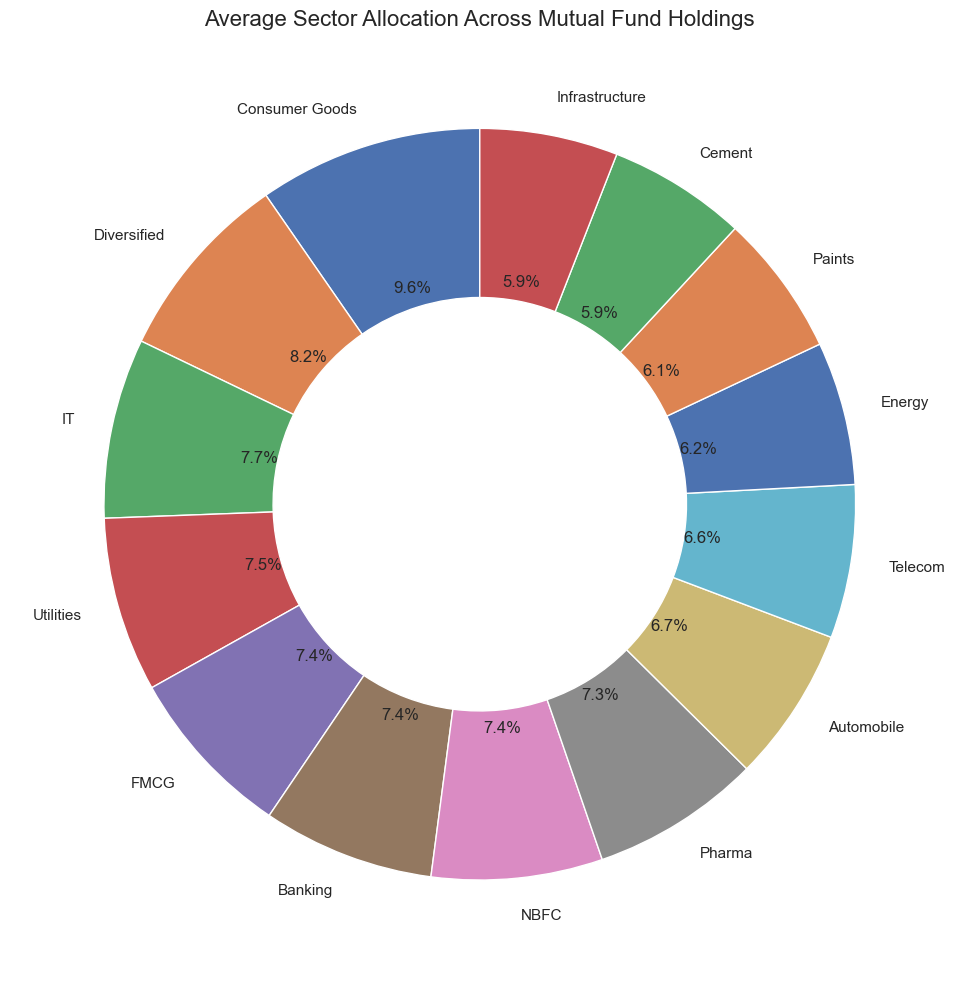

Chart 12 saved successfully!


In [38]:
plt.figure(figsize=(10, 10))

plt.pie(
    sector_allocation,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)

plt.title("Average Sector Allocation Across Mutual Fund Holdings", fontsize=16)
plt.tight_layout()

plt.savefig(
    charts_path / "chart12_sector_allocation_donut.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 12 saved successfully!")

### EDA Finding #9 — Sector-wise Portfolio Allocation

- Portfolio holdings are distributed across multiple sectors.
- The donut chart visualizes the average sector weight across the available mutual fund holdings.
- Sector allocation helps understand portfolio concentration and diversification.
- Higher allocation to a particular sector may expose a portfolio to sector-specific risks.
- Chart Reference: chart12_sector_allocation_donut.png

In [39]:
sip_df = pd.read_csv(
    processed_path / "monthly_sip_inflows_cleaned.csv"
)

sip_df["month"] = pd.to_datetime(sip_df["month"])
sip_df = sip_df.sort_values("month")

display(sip_df[["month", "sip_aum_lakh_crore"]].head())
print("Total records:", len(sip_df))

,month,sip_aum_lakh_crore
0,2022-01-01,4.80
1,2022-02-01,4.85
2,2022-03-01,5.01
3,2022-04-01,5.12
4,2022-05-01,5.15


Total records: 48


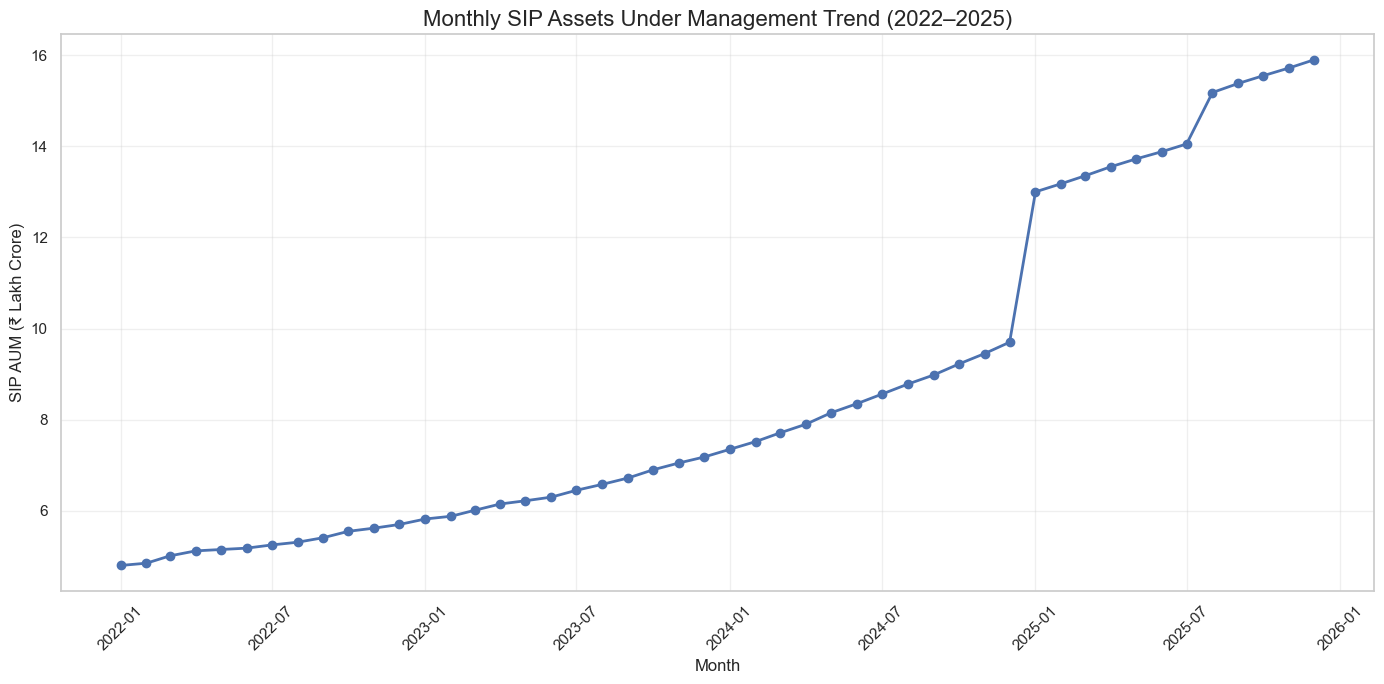

In [40]:
plt.figure(figsize=(14, 7))

plt.plot(
    sip_df["month"],
    sip_df["sip_aum_lakh_crore"],
    marker="o",
    linewidth=2
)

plt.title("Monthly SIP Assets Under Management Trend (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("SIP AUM (₹ Lakh Crore)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

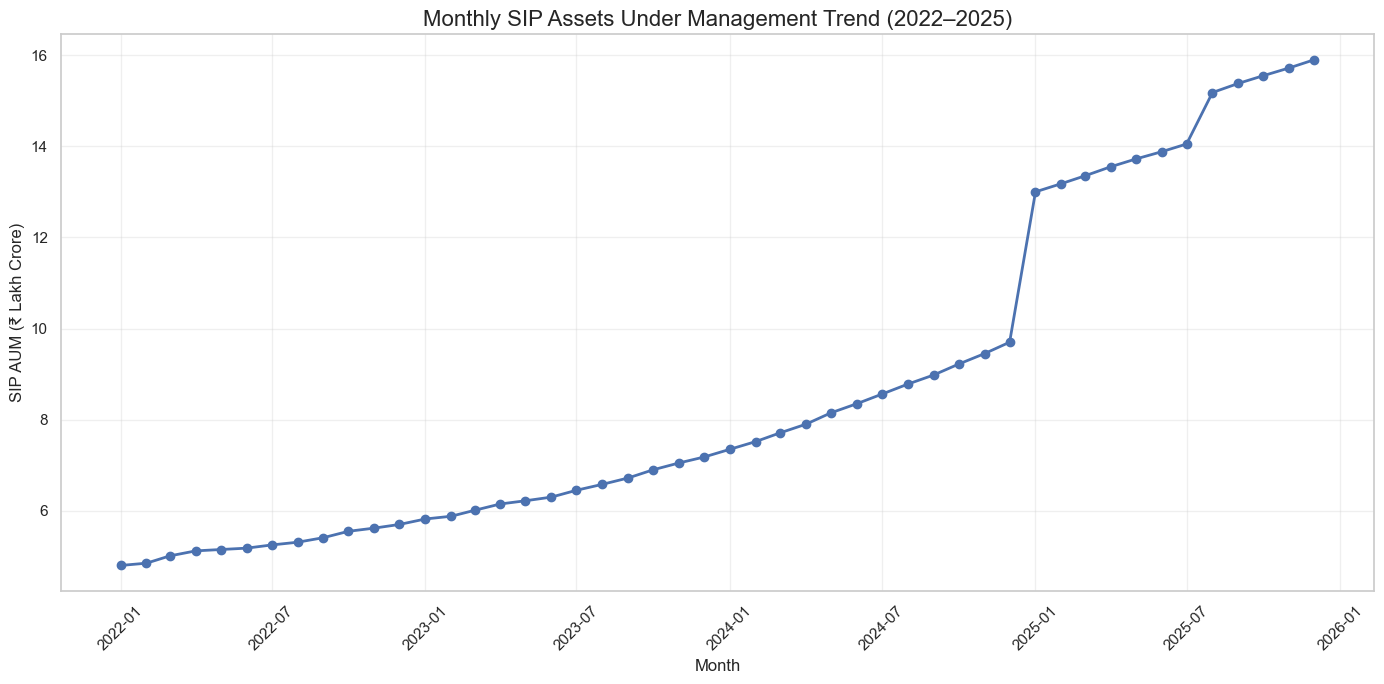

Chart 13 saved successfully!


In [41]:
plt.figure(figsize=(14, 7))

plt.plot(
    sip_df["month"],
    sip_df["sip_aum_lakh_crore"],
    marker="o",
    linewidth=2
)

plt.title("Monthly SIP Assets Under Management Trend (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("SIP AUM (₹ Lakh Crore)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    charts_path / "chart13_sip_aum_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 13 saved successfully!")

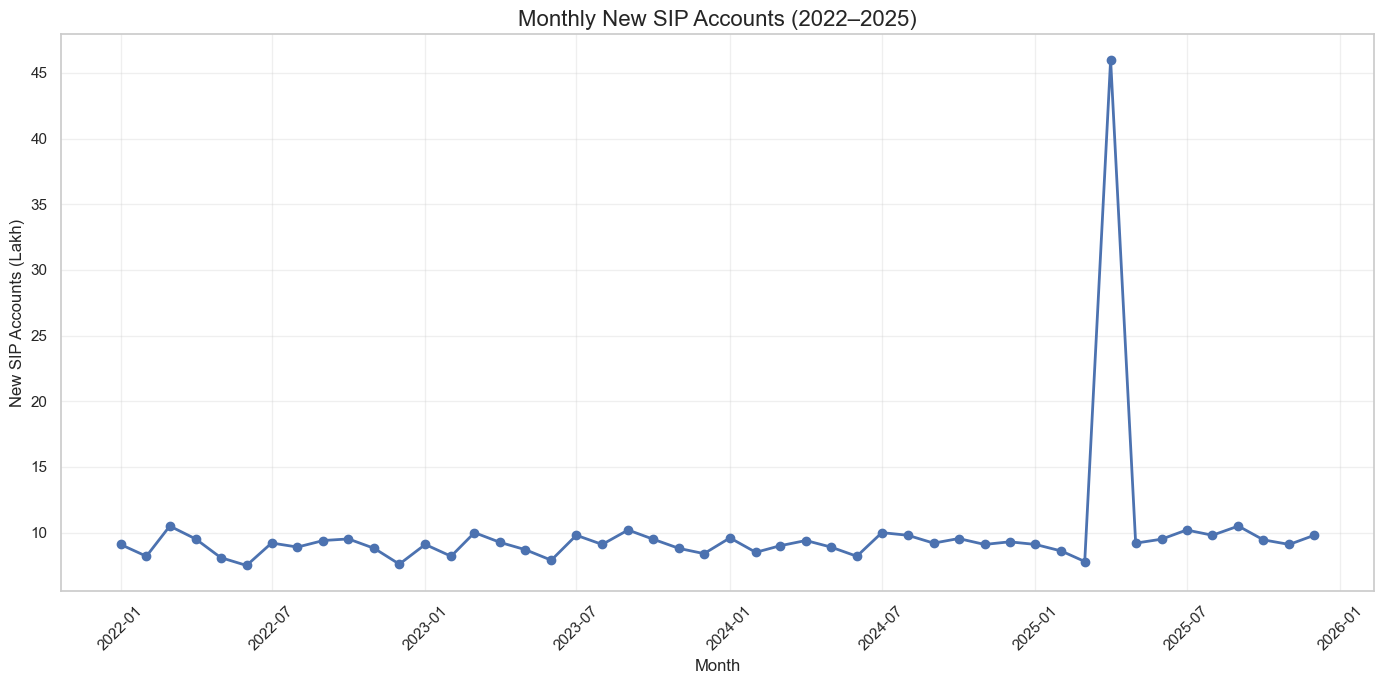

In [42]:
plt.figure(figsize=(14, 7))

plt.plot(
    sip_df["month"],
    sip_df["new_sip_accounts_lakh"],
    marker="o",
    linewidth=2
)

plt.title("Monthly New SIP Accounts (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("New SIP Accounts (Lakh)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

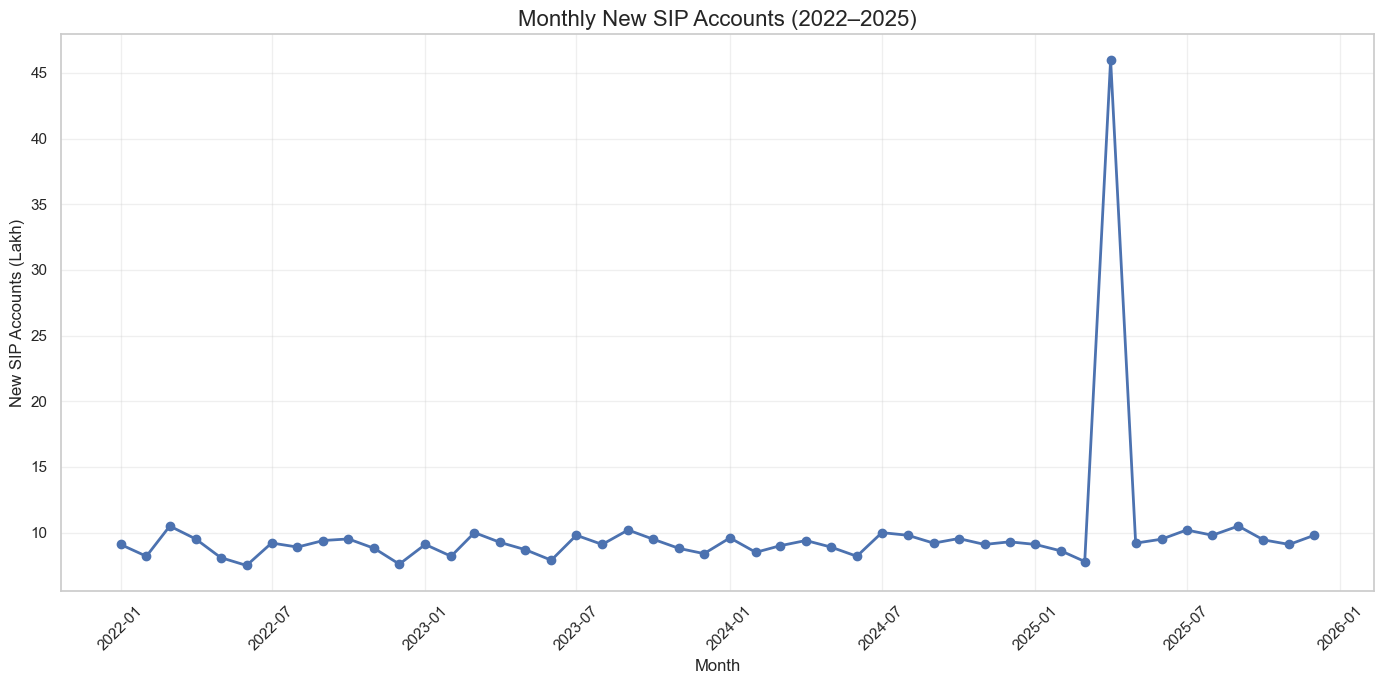

Chart 14 saved successfully!


In [43]:
plt.figure(figsize=(14, 7))

plt.plot(
    sip_df["month"],
    sip_df["new_sip_accounts_lakh"],
    marker="o",
    linewidth=2
)

plt.title("Monthly New SIP Accounts (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("New SIP Accounts (Lakh)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    charts_path / "chart14_new_sip_accounts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 14 saved successfully!")

In [44]:
performance_df = pd.read_csv(
    processed_path / "scheme_performance_cleaned.csv"
)

display(performance_df.head())
print("Columns:", performance_df.columns.tolist())

,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade,return_anomaly
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate,False
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate,False
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High,False
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,Direct,20.59,23.14,21.82,22.01,1.13,1.04,0.93,1.67,25.0,-24.78,36061,0.72,4,Very High,False
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,SBI Mutual Fund,Gilt,Regular,5.34,6.07,5.43,4.47,1.60,0.22,1.52,2.11,4.0,-2.30,24101,0.77,5,Low,False


Columns: ['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade', 'return_anomaly']


In [45]:
print(performance_df[["scheme_name", "return_1yr_pct", "return_3yr_pct", "return_5yr_pct"]].head(10))

                                         scheme_name  return_1yr_pct  \
0          SBI Bluechip Fund - Regular Plan - Growth           12.42   
1           SBI Bluechip Fund - Direct Plan - Growth           15.25   
2         SBI Small Cap Fund - Regular Plan - Growth           24.56   
3          SBI Small Cap Fund - Direct Plan - Growth           20.59   
4       SBI Magnum Gilt Fund - Regular Plan - Growth            5.34   
5          HDFC Top 100 Fund - Regular Plan - Growth           10.94   
6           HDFC Top 100 Fund - Direct Plan - Growth           11.48   
7  HDFC Mid-Cap Opportunities Fund - Regular - Gr...           15.43   
8  HDFC Mid-Cap Opportunities Fund - Direct - Growth           19.98   
9       HDFC Short Term Debt Fund - Regular - Growth            6.83   

   return_3yr_pct  return_5yr_pct  
0           12.36           14.45  
1           11.30           14.23  
2           23.39           20.67  
3           23.14           21.82  
4            6.07          

In [46]:
top10_returns = (
    performance_df
    .sort_values("return_3yr_pct", ascending=False)
    .head(10)
)

display(top10_returns[["scheme_name", "return_3yr_pct"]])

,scheme_name,return_3yr_pct
2,SBI Small Cap Fund - Regular Plan - Growth,23.39
3,SBI Small Cap Fund - Direct Plan - Growth,23.14
29,ABSL Small Cap Fund - Regular - Growth,22.38
27,Axis Small Cap Fund - Regular - Growth,20.98
17,Nippon India Small Cap Fund - Regular - Growth,20.15
39,DSP Small Cap Fund - Regular - Growth,20.08
21,Kotak Emerging Equity Fund - Regular - Growth,18.23
12,ICICI Pru Midcap Fund - Regular - Growth,18.08
38,DSP Midcap Fund - Regular - Growth,17.16
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,16.58


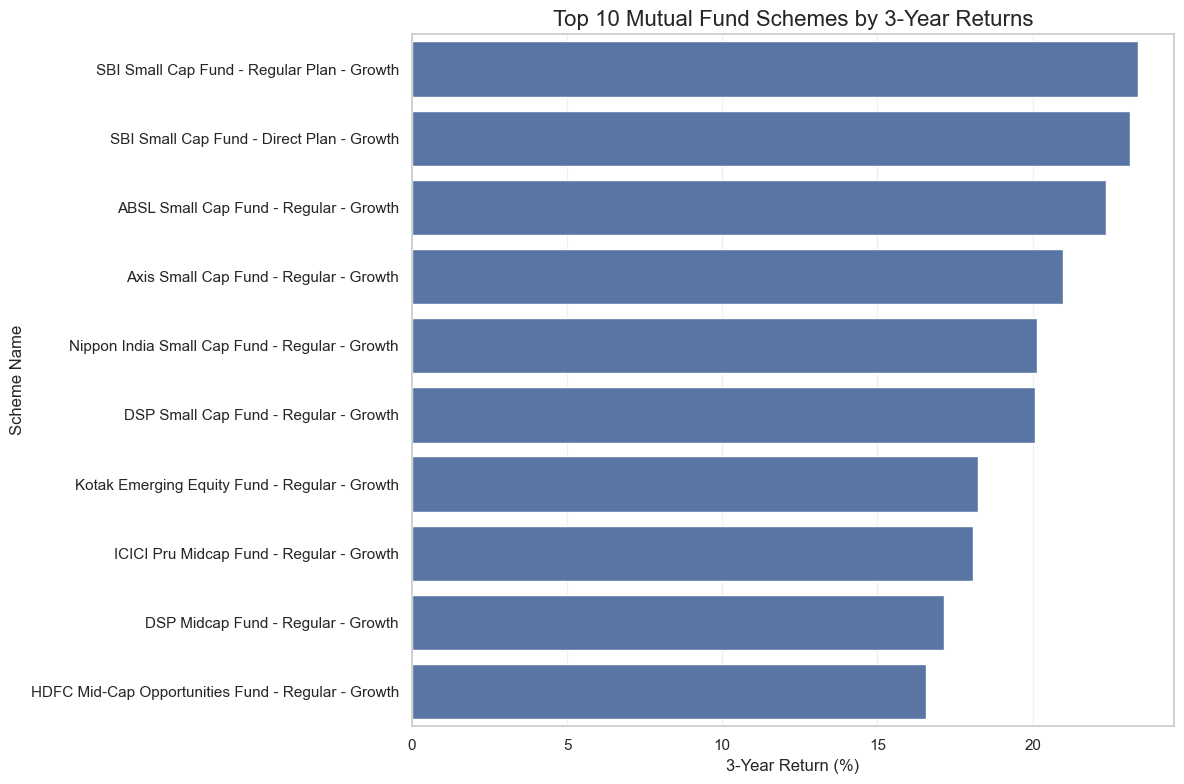

In [47]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top10_returns,
    x="return_3yr_pct",
    y="scheme_name"
)

plt.title("Top 10 Mutual Fund Schemes by 3-Year Returns", fontsize=16)
plt.xlabel("3-Year Return (%)")
plt.ylabel("Scheme Name")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

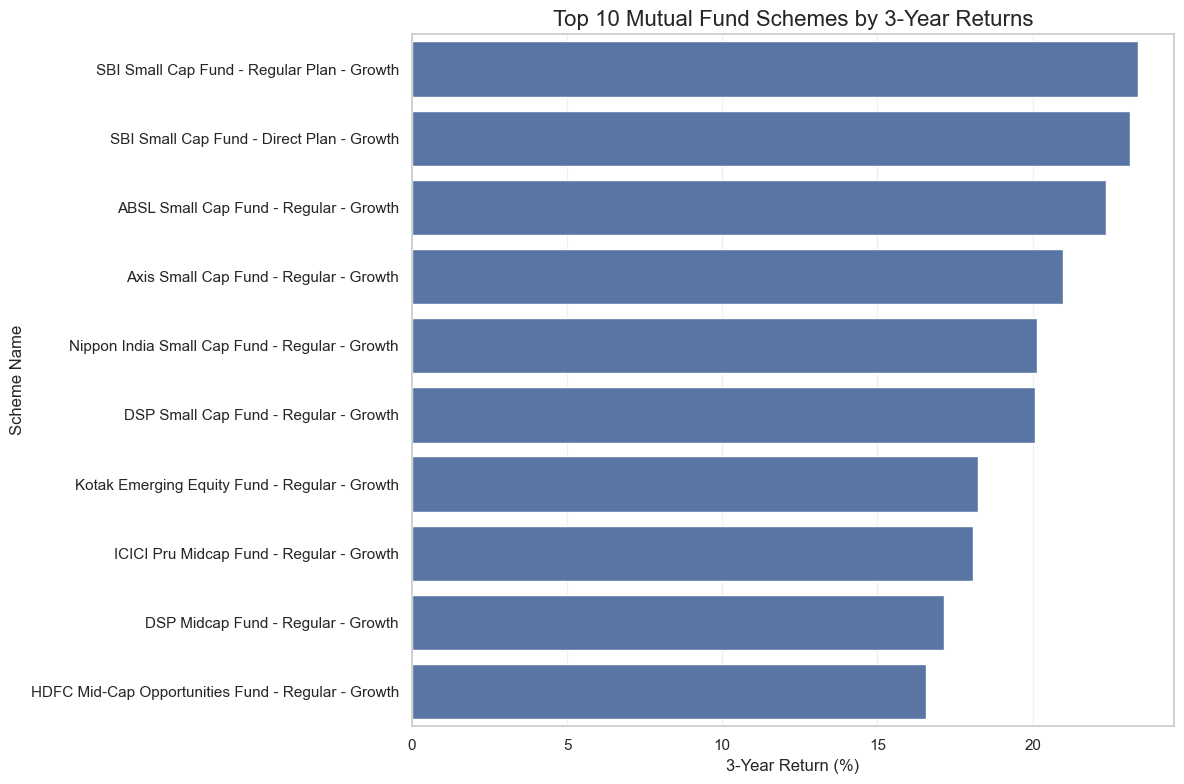

Chart 15 saved successfully!


In [48]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top10_returns,
    x="return_3yr_pct",
    y="scheme_name"
)

plt.title("Top 10 Mutual Fund Schemes by 3-Year Returns", fontsize=16)
plt.xlabel("3-Year Return (%)")
plt.ylabel("Scheme Name")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    charts_path / "chart15_top10_3yr_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart 15 saved successfully!")

### EDA Finding #10 — Overall Mutual Fund Market Insights

- Mutual fund market indicators show changes in investor participation, SIP activity, folio growth and assets under management over the analysis period.
- SIP trends help understand recurring investment activity and investor participation.
- Investor demographics and geographic charts highlight differences in transaction patterns across age groups, genders, states and city tiers.
- Fund performance and NAV correlation analysis provide insights into return behavior and relationships between selected schemes.
- Sector allocation analysis helps understand the distribution and concentration of portfolio holdings.
- These findings are based on the datasets available in the project and should not be treated as a complete representation of the entire Indian mutual fund market.

In [49]:
chart_files = sorted(charts_path.glob("*"))

print("Total chart files:", len(chart_files))
print("\nFiles saved in charts folder:\n")

for file in chart_files:
    print(file.name)

Total chart files: 16

Files saved in charts folder:

chart01_nav_trends.html
chart02_aum_by_fund_house.png
chart03_monthly_sip_inflows.html
chart03_monthly_sip_inflows.png
chart04_category_inflow_heatmap.png
chart05_age_distribution.png
chart06_amount_by_age_group.png
chart07_gender_distribution.png
chart08_statewise_sip.png
chart09_city_tier_distribution.png
chart10_folio_growth.png
chart11_nav_returns_correlation.png
chart12_sector_allocation_donut.png
chart13_sip_aum_trend.png
chart14_new_sip_accounts.png
chart15_top10_3yr_returns.png


In [50]:
nav_export = pd.read_csv(processed_path / "nav_history_cleaned.csv")
fund_export = pd.read_csv(processed_path / "fund_master_cleaned.csv")

nav_export["date"] = pd.to_datetime(nav_export["date"])
nav_export["amfi_code"] = nav_export["amfi_code"].astype(str)
fund_export["amfi_code"] = fund_export["amfi_code"].astype(str)

nav_export = nav_export.merge(
    fund_export[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

fig_nav_export = px.line(
    nav_export,
    x="date",
    y="nav",
    color="scheme_name",
    title="NAV Trends Across Mutual Fund Schemes (2022–2026)"
)

fig_nav_export.update_layout(
    template="plotly_white",
    height=700
)

fig_nav_export.write_image(
    str(charts_path / "chart01_nav_trends.png"),
    width=1600,
    height=900,
    scale=2
)

print("Chart 1 PNG exported successfully!")

Chart 1 PNG exported successfully!


In [51]:
png_files = sorted(charts_path.glob("*.png"))
html_files = sorted(charts_path.glob("*.html"))

print("PNG charts:", len(png_files))
print("Interactive HTML charts:", len(html_files))
print("\nPNG files:")
for f in png_files:
    print("✅", f.name)

print("\nHTML files:")
for f in html_files:
    print("✅", f.name)

PNG charts: 15
Interactive HTML charts: 2

PNG files:
✅ chart01_nav_trends.png
✅ chart02_aum_by_fund_house.png
✅ chart03_monthly_sip_inflows.png
✅ chart04_category_inflow_heatmap.png
✅ chart05_age_distribution.png
✅ chart06_amount_by_age_group.png
✅ chart07_gender_distribution.png
✅ chart08_statewise_sip.png
✅ chart09_city_tier_distribution.png
✅ chart10_folio_growth.png
✅ chart11_nav_returns_correlation.png
✅ chart12_sector_allocation_donut.png
✅ chart13_sip_aum_trend.png
✅ chart14_new_sip_accounts.png
✅ chart15_top10_3yr_returns.png

HTML files:
✅ chart01_nav_trends.html
✅ chart03_monthly_sip_inflows.html
